# Micro-Expression Spotting v2 (POC-ABS + apex/ module)
Onset–Apex–Offset detection using `apex/` classes (`ApexPhase`, `ApexSmoother`, `ApexPhaseVisualizer`)

### Pipeline (Per-Question: 1B → 2B → 3B)
1. **Step 1B** — Extract frames per question (q1–q5) → save to disk
2. **Step 2B** — Load frame pairs → face detection → ROI → POC-ABS magnitude → save `.npy`
3. **Step 3B** — Load magnitudes → adaptive smooth → apex detection → onset/offset → plot

In [3]:
import cv2
import dlib
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import re
import gc

PROJECT_ROOT = os.path.abspath("..")
sys.path.insert(0, PROJECT_ROOT)

from features_extraction.poc import POC
from features_extraction.vektor import Vektor
from features_extraction.quadran import Quadran

# apex/ module classes
from apex import ApexPhase, ApexSmoother, ApexPhaseVisualizer

In [4]:
# ======================================================
# CONFIGURATION
# ======================================================
ROOT_DIR = "../dataset"
OUTPUT_DIR = "../output"
FRAMES_DIR_Q = os.path.join(OUTPUT_DIR, "frames_per_q")
MAGNITUDES_DIR_Q = os.path.join(OUTPUT_DIR, "magnitudes_per_q")
PLOTS_DIR_Q = os.path.join(OUTPUT_DIR, "plots_per_q_v2")
PREDICTOR_PATH = "./models/shape_predictor_68_face_landmarks.dat"

BLOCK_SIZE = 7

# ROI definitions (dlib 68-landmark indices)
REGIONS = {
    "mata_kanan":  list(range(42, 48)),
    "mata_kiri":   list(range(36, 42)),
    "alis_kanan":  list(range(22, 27)),
    "alis_kiri":   list(range(17, 22)),
    "mulut":       list(range(48, 68)),
}

TARGET_SIZE = {
    "mata_kanan":  (48, 32),
    "mata_kiri":   (48, 32),
    "alis_kanan":  (48, 20),
    "alis_kiri":   (48, 20),
    "mulut":       (70, 35),
}

PADDING_X = 6
PADDING_Y = 8

def natural_sort_key(s):
    return [int(t) if t.isdigit() else t.lower()
            for t in re.split(r'(\\d+)', s)]

# Create output dirs
for d in [FRAMES_DIR_Q, MAGNITUDES_DIR_Q, PLOTS_DIR_Q]:
    os.makedirs(d, exist_ok=True)

print("✅ Configuration ready")

✅ Configuration ready


## Step 1B: Extract Frames (Per Question)
Read each q1–q5 `.avi` separately per subject, save frames to disk.

In [ ]:
# ======================================================
# STEP 1B: EXTRACT FRAMES (Separated per Question)
# ======================================================

q_count = 0

for label in sorted(os.listdir(ROOT_DIR)):
    label_path = os.path.join(ROOT_DIR, label)
    if not os.path.isdir(label_path):
        continue

    for subject_name in sorted(os.listdir(label_path), key=natural_sort_key):
        subject_path = os.path.join(label_path, subject_name)
        if not os.path.isdir(subject_path):
            continue

        q_dirs = sorted(
            [d for d in os.listdir(subject_path) if os.path.isdir(os.path.join(subject_path, d))],
            key=natural_sort_key
        )

        for q_dir in q_dirs:
            output_name = f"{label}_{subject_name}_{q_dir}"
            frames_out = os.path.join(FRAMES_DIR_Q, output_name)

            if os.path.isdir(frames_out) and len(os.listdir(frames_out)) > 0:
                print(f"⏩ Skip {output_name}: frames already extracted")
                q_count += 1
                continue

            os.makedirs(frames_out, exist_ok=True)

            q_path = os.path.join(subject_path, q_dir)
            avi_files = sorted(
                [f for f in os.listdir(q_path) if f.lower().endswith(".avi")],
                key=natural_sort_key
            )

            frame_idx = 0
            for avi in avi_files:
                cap = cv2.VideoCapture(os.path.join(q_path, avi))
                while True:
                    ret, frame = cap.read()
                    if not ret:
                        break
                    fname = os.path.join(frames_out, f"frame_{frame_idx:05d}.jpg")
                    cv2.imwrite(fname, frame)
                    frame_idx += 1
                cap.release()

            if frame_idx > 0:
                print(f"✅ {output_name}: {frame_idx} frames saved")
                q_count += 1
            else:
                try:
                    os.rmdir(frames_out)
                except:
                    pass
            gc.collect()

print(f"\n🎉 Step 1B done! {q_count} question segments processed. Frames in {FRAMES_DIR_Q}/")

## Step 2B: Compute POC-ABS Magnitudes (Per Question)
Load frame pairs, detect face, extract ROIs, compute POC-ABS magnitude, save `.npy`.

In [ ]:
# ======================================================
# STEP 2B: SETUP — Load dlib models + helper functions
# ======================================================

if not os.path.exists(PREDICTOR_PATH):
    raise FileNotFoundError(f"Predictor tidak ditemukan: {PREDICTOR_PATH}")

detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(PREDICTOR_PATH)
print("✅ Dlib models loaded")

def extract_region(image, landmarks, indices):
    pts = [(landmarks.part(i).x, landmarks.part(i).y) for i in indices]
    xs, ys = zip(*pts)
    left   = max(0, min(xs) - PADDING_X)
    top    = max(0, min(ys) - PADDING_Y)
    right  = min(image.shape[1], max(xs) + PADDING_X)
    bottom = min(image.shape[0], max(ys) + PADDING_Y)
    return image[top:bottom, left:right]

def detect_landmarks(gray):
    faces = detector(gray)
    if len(faces) > 0:
        return predictor(gray, faces[0])
    return None

def compute_frame_magnitude(prev_gray, prev_lm, curr_gray, curr_lm):
    roi_mags = []
    for region_name, lm_indices in REGIONS.items():
        try:
            roi_prev = extract_region(prev_gray, prev_lm, lm_indices)
            roi_curr = extract_region(curr_gray, curr_lm, lm_indices)

            if roi_prev.size == 0 or roi_curr.size == 0:
                return 0.0

            target = TARGET_SIZE[region_name]
            roi_prev = cv2.resize(roi_prev, target)
            roi_curr = cv2.resize(roi_curr, target)

            poc = POC(roi_prev, roi_curr, BLOCK_SIZE)
            vec = Vektor(poc.getPOC(), BLOCK_SIZE)
            quad_data = Quadran(vec.getVektor()).getQuadran()

            magnitudes = [float(block[4]) for block in quad_data]
            roi_mags.append(np.mean(magnitudes) if magnitudes else 0.0)
        except Exception:
            return 0.0

    return np.mean(roi_mags) if roi_mags else 0.0

In [ ]:
# ======================================================
# STEP 2B: COMPUTE MAGNITUDES (Per Question)
# ======================================================

q_count = 0

for q_folder in sorted(os.listdir(FRAMES_DIR_Q), key=natural_sort_key):
    q_frames_dir = os.path.join(FRAMES_DIR_Q, q_folder)
    if not os.path.isdir(q_frames_dir):
        continue

    npy_path = os.path.join(MAGNITUDES_DIR_Q, f"{q_folder}.npy")

    if os.path.exists(npy_path):
        print(f"⏩ Skip {q_folder}: magnitudes already computed")
        q_count += 1
        continue

    frame_files = sorted(
        [f for f in os.listdir(q_frames_dir) if f.endswith(".jpg")],
        key=natural_sort_key
    )

    if len(frame_files) < 3:
        print(f"⚠️  Skip {q_folder}: too few frames ({len(frame_files)})")
        continue

    print(f"🔄 Processing {q_folder} ({len(frame_files)} frames)...")

    magnitude_list = []

    prev_gray = cv2.imread(os.path.join(q_frames_dir, frame_files[0]), cv2.IMREAD_GRAYSCALE)
    prev_lm = detect_landmarks(prev_gray)

    for i in range(1, len(frame_files)):
        curr_gray = cv2.imread(os.path.join(q_frames_dir, frame_files[i]), cv2.IMREAD_GRAYSCALE)
        curr_lm = detect_landmarks(curr_gray)

        if prev_lm is not None and curr_lm is not None:
            mag = compute_frame_magnitude(prev_gray, prev_lm, curr_gray, curr_lm)
        else:
            mag = 0.0

        magnitude_list.append(mag)
        prev_gray = curr_gray
        prev_lm = curr_lm

    np.save(npy_path, np.array(magnitude_list, dtype=float))
    print(f"✅ {q_folder}: {len(magnitude_list)} magnitudes saved")
    q_count += 1
    gc.collect()

print(f"\n🎉 Step 2B done! {q_count} segments processed. Magnitudes in {MAGNITUDES_DIR_Q}/")

## Step 3B: Analyze & Visualize (Per Question) — Using `apex/` Module
Uses `ApexSmoother` for adaptive window, `ApexPhase` for peak + phase detection, `ApexPhaseVisualizer` for plotting.

🔍 anxiety-rendah_ahmad_rifqi_hendriansyah_1765181629492_q1 | frames=483 | window=25 | polyorder=4
  ✅ Apex: 227 | Onset: 213 | Offset: 232 | Duration: 19
  ✅ Apex: 243 | Onset: 236 | Offset: 250 | Duration: 14
  ✅ Apex: 270 | Onset: 259 | Offset: 278 | Duration: 19
  ✅ Apex: 287 | Onset: 282 | Offset: 291 | Duration: 9
  ✅ Apex: 418 | Onset: 398 | Offset: 435 | Duration: 37
  ✅ Apex: 476 | Onset: 463 | Offset: 482 | Duration: 19


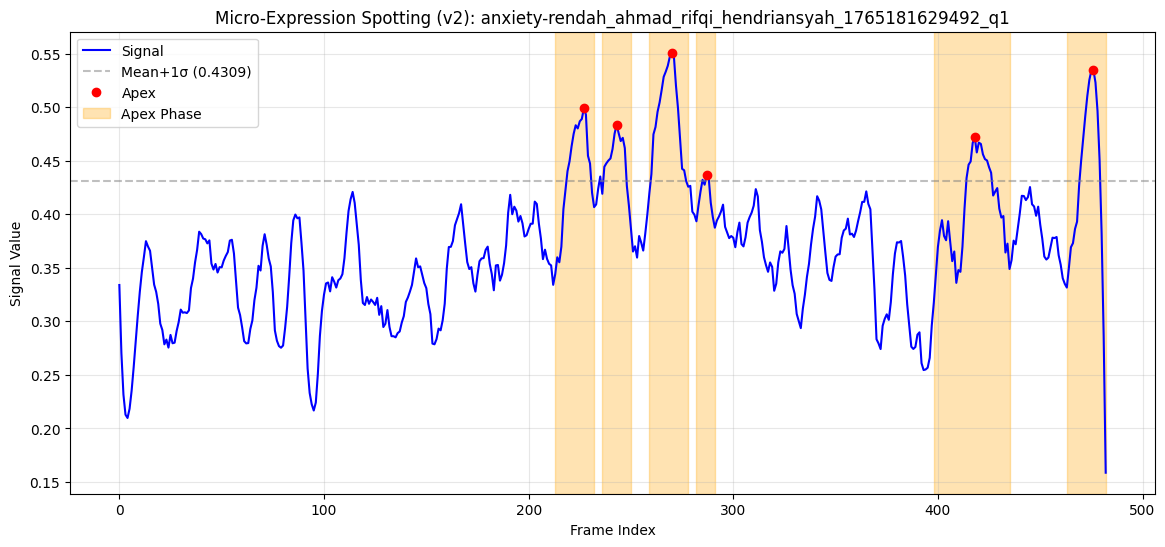

🔍 anxiety-rendah_ahmad_rifqi_hendriansyah_1765181629492_q2 | frames=325 | window=17 | polyorder=4
  ✅ Apex: 14 | Onset: 9 | Offset: 21 | Duration: 12
  ✅ Apex: 116 | Onset: 109 | Offset: 121 | Duration: 12
  ✅ Apex: 127 | Onset: 123 | Offset: 130 | Duration: 7
  ✅ Apex: 137 | Onset: 132 | Offset: 143 | Duration: 11
  ✅ Apex: 182 | Onset: 177 | Offset: 186 | Duration: 9
  ✅ Apex: 270 | Onset: 263 | Offset: 282 | Duration: 19
  ✅ Apex: 299 | Onset: 286 | Offset: 319 | Duration: 33


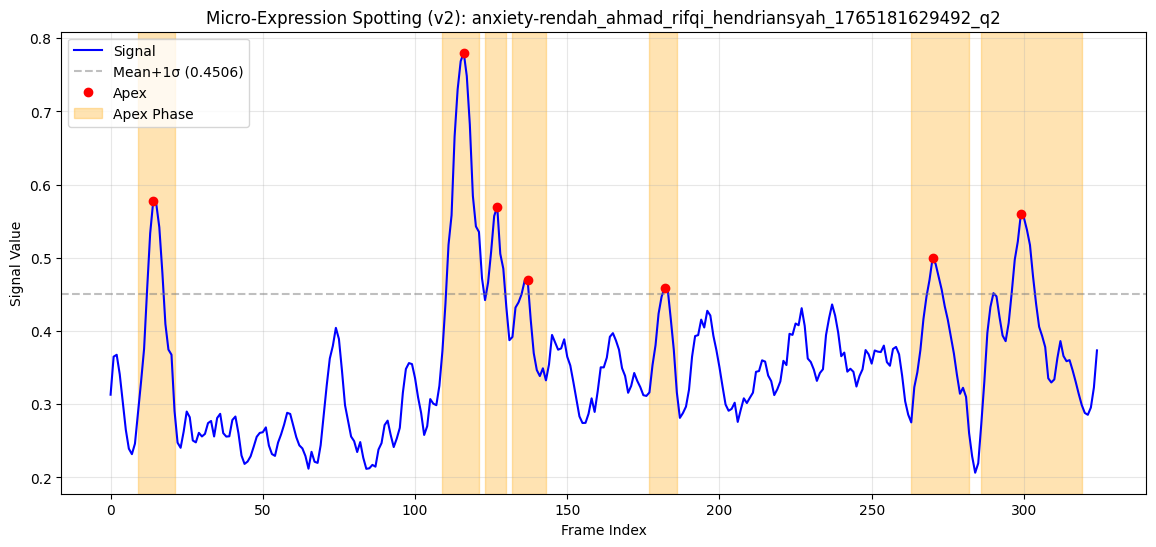

🔍 anxiety-rendah_ahmad_rifqi_hendriansyah_1765181629492_q3 | frames=340 | window=17 | polyorder=4
  ✅ Apex: 11 | Onset: 5 | Offset: 22 | Duration: 17
  ✅ Apex: 45 | Onset: 40 | Offset: 49 | Duration: 9
  ✅ Apex: 57 | Onset: 52 | Offset: 83 | Duration: 31
  ✅ Apex: 156 | Onset: 139 | Offset: 162 | Duration: 23
  ✅ Apex: 177 | Onset: 169 | Offset: 183 | Duration: 14
  ✅ Apex: 191 | Onset: 187 | Offset: 197 | Duration: 10
  ✅ Apex: 232 | Onset: 219 | Offset: 239 | Duration: 20
  ✅ Apex: 272 | Onset: 265 | Offset: 276 | Duration: 11
  ✅ Apex: 284 | Onset: 280 | Offset: 290 | Duration: 10
  ✅ Apex: 298 | Onset: 293 | Offset: 299 | Duration: 6
  ✅ Apex: 314 | Onset: 306 | Offset: 319 | Duration: 13


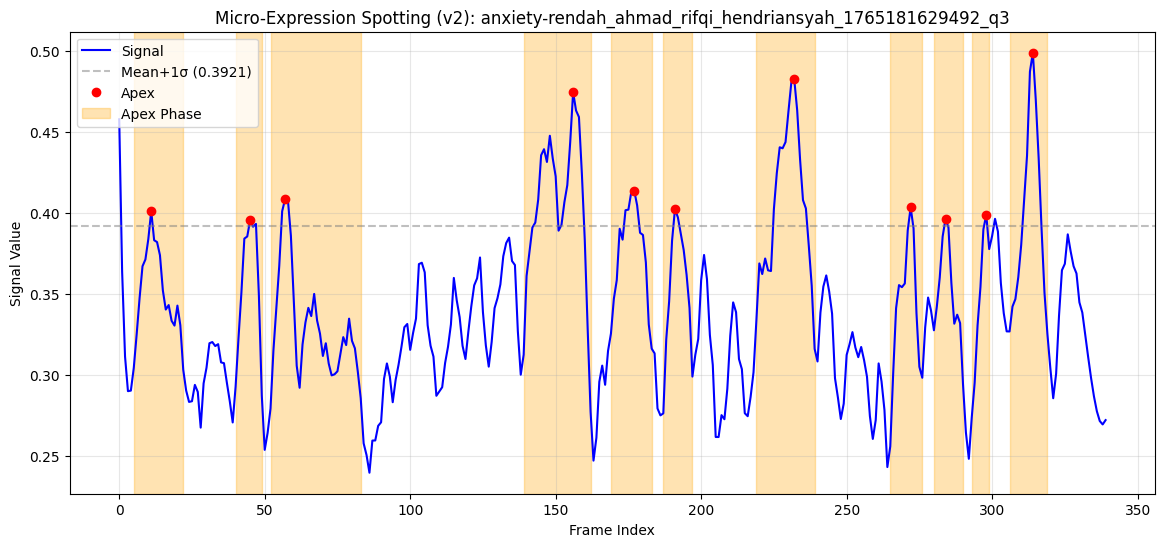

🔍 anxiety-rendah_ahmad_rifqi_hendriansyah_1765181629492_q4 | frames=298 | window=15 | polyorder=3
  ✅ Apex: 91 | Onset: 67 | Offset: 120 | Duration: 53
  ✅ Apex: 203 | Onset: 202 | Offset: 208 | Duration: 6
  ✅ Apex: 246 | Onset: 239 | Offset: 252 | Duration: 13
  ✅ Apex: 260 | Onset: 257 | Offset: 266 | Duration: 9
  ✅ Apex: 274 | Onset: 269 | Offset: 281 | Duration: 12


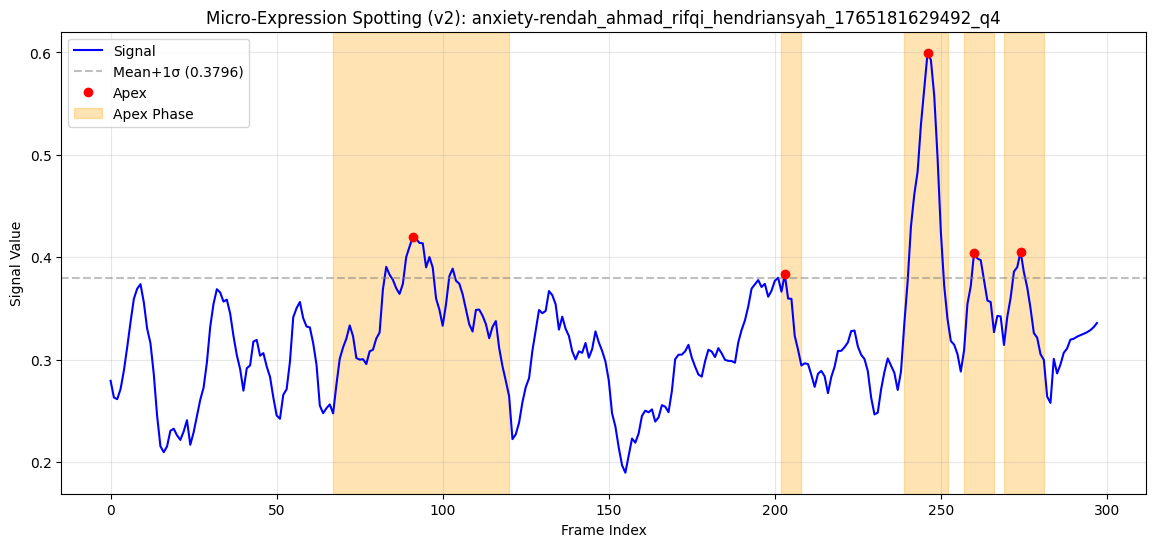

🔍 anxiety-rendah_ahmad_rifqi_hendriansyah_1765181629492_q5 | frames=402 | window=21 | polyorder=4
  ✅ Apex: 17 | Onset: 1 | Offset: 39 | Duration: 38
  ✅ Apex: 68 | Onset: 61 | Offset: 75 | Duration: 14
  ✅ Apex: 127 | Onset: 109 | Offset: 132 | Duration: 23
  ✅ Apex: 139 | Onset: 134 | Offset: 144 | Duration: 10
  ✅ Apex: 156 | Onset: 149 | Offset: 164 | Duration: 15
  ✅ Apex: 243 | Onset: 236 | Offset: 249 | Duration: 13
  ✅ Apex: 276 | Onset: 270 | Offset: 282 | Duration: 12
  ✅ Apex: 333 | Onset: 328 | Offset: 339 | Duration: 11
  ✅ Apex: 386 | Onset: 377 | Offset: 392 | Duration: 15
  ✅ Apex: 400 | Onset: 395 | Offset: 401 | Duration: 6


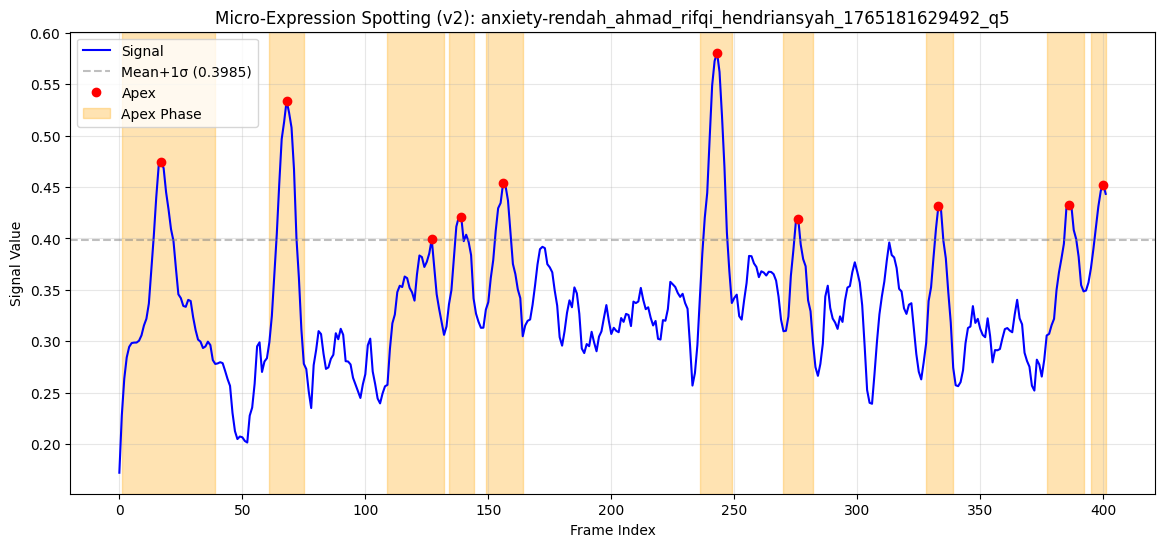

🔍 anxiety-rendah_akhmad_aakhif_athallah_1765186538689_q1 | frames=529 | window=27 | polyorder=4
  ✅ Apex: 48 | Onset: 15 | Offset: 72 | Duration: 57
  ✅ Apex: 119 | Onset: 102 | Offset: 126 | Duration: 24
  ✅ Apex: 134 | Onset: 130 | Offset: 137 | Duration: 7
  ✅ Apex: 249 | Onset: 240 | Offset: 262 | Duration: 22
  ✅ Apex: 275 | Onset: 267 | Offset: 280 | Duration: 13
  ✅ Apex: 290 | Onset: 286 | Offset: 300 | Duration: 14
  ✅ Apex: 310 | Onset: 301 | Offset: 317 | Duration: 16
  ✅ Apex: 389 | Onset: 380 | Offset: 412 | Duration: 32
  ✅ Apex: 442 | Onset: 415 | Offset: 449 | Duration: 34
  ✅ Apex: 497 | Onset: 480 | Offset: 504 | Duration: 24
  ✅ Apex: 520 | Onset: 511 | Offset: 528 | Duration: 17


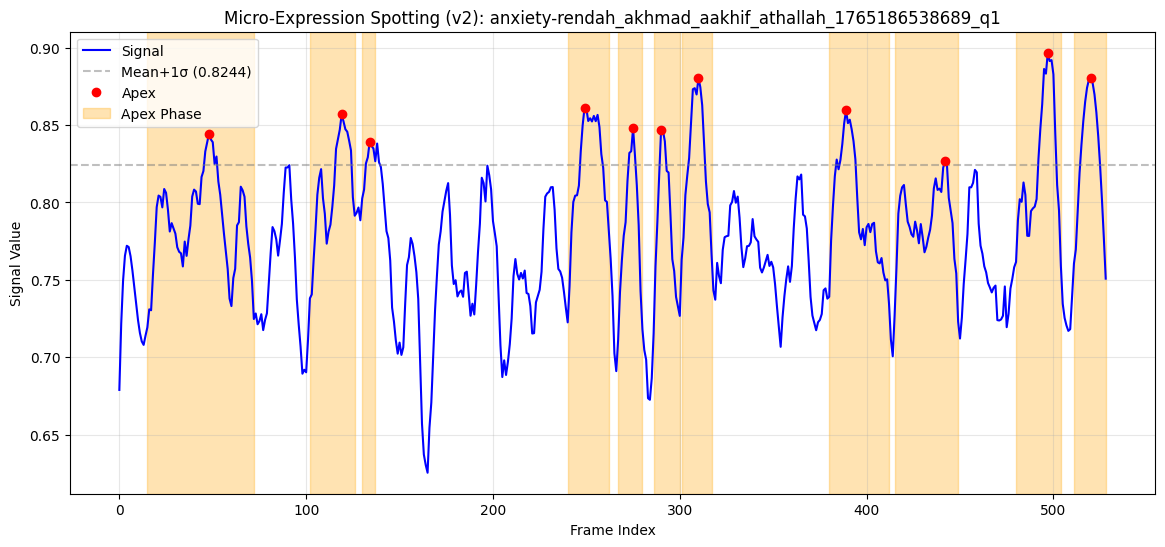

🔍 anxiety-rendah_akhmad_aakhif_athallah_1765186538689_q2 | frames=530 | window=27 | polyorder=4
  ✅ Apex: 117 | Onset: 81 | Offset: 124 | Duration: 43
  ✅ Apex: 135 | Onset: 128 | Offset: 139 | Duration: 11
  ✅ Apex: 151 | Onset: 143 | Offset: 157 | Duration: 14
  ✅ Apex: 173 | Onset: 165 | Offset: 178 | Duration: 13
  ✅ Apex: 211 | Onset: 201 | Offset: 218 | Duration: 17
  ✅ Apex: 228 | Onset: 225 | Offset: 238 | Duration: 13
  ✅ Apex: 253 | Onset: 240 | Offset: 263 | Duration: 23
  ✅ Apex: 376 | Onset: 369 | Offset: 384 | Duration: 15
  ✅ Apex: 463 | Onset: 449 | Offset: 471 | Duration: 22
  ✅ Apex: 514 | Onset: 506 | Offset: 527 | Duration: 21


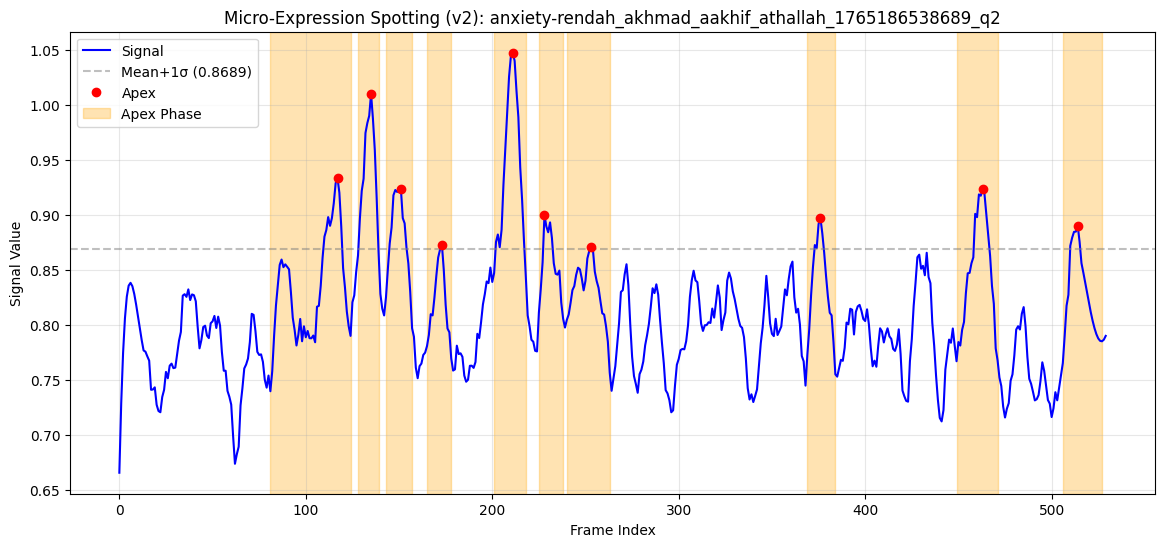

🔍 anxiety-rendah_akhmad_aakhif_athallah_1765186538689_q3 | frames=852 | window=31 | polyorder=4
  ✅ Apex: 47 | Onset: 29 | Offset: 63 | Duration: 34
  ✅ Apex: 83 | Onset: 76 | Offset: 94 | Duration: 18
  ✅ Apex: 150 | Onset: 141 | Offset: 157 | Duration: 16
  ✅ Apex: 197 | Onset: 191 | Offset: 206 | Duration: 15
  ✅ Apex: 385 | Onset: 378 | Offset: 395 | Duration: 17
  ✅ Apex: 490 | Onset: 482 | Offset: 499 | Duration: 17
  ✅ Apex: 517 | Onset: 511 | Offset: 525 | Duration: 14
  ✅ Apex: 568 | Onset: 558 | Offset: 587 | Duration: 29
  ✅ Apex: 637 | Onset: 629 | Offset: 647 | Duration: 18
  ✅ Apex: 709 | Onset: 697 | Offset: 714 | Duration: 17
  ✅ Apex: 751 | Onset: 740 | Offset: 763 | Duration: 23
  ✅ Apex: 782 | Onset: 776 | Offset: 790 | Duration: 14
  ✅ Apex: 801 | Onset: 791 | Offset: 808 | Duration: 17
  ✅ Apex: 824 | Onset: 815 | Offset: 840 | Duration: 25


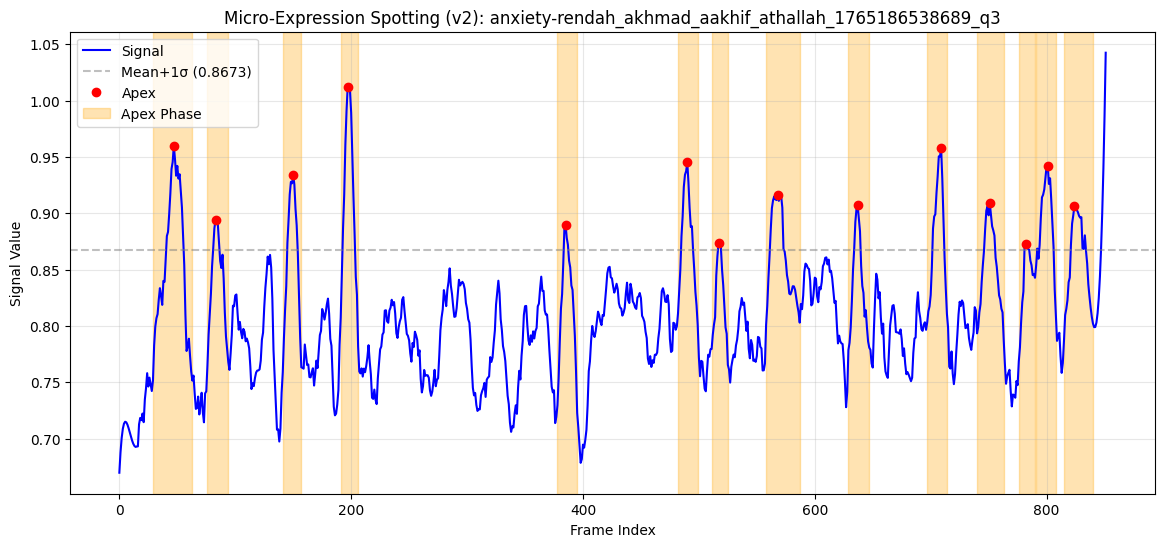

🔍 anxiety-rendah_akhmad_aakhif_athallah_1765186538689_q4 | frames=612 | window=31 | polyorder=4
  ✅ Apex: 17 | Onset: 2 | Offset: 24 | Duration: 22
  ✅ Apex: 98 | Onset: 85 | Offset: 114 | Duration: 29
  ✅ Apex: 224 | Onset: 216 | Offset: 235 | Duration: 19
  ✅ Apex: 291 | Onset: 282 | Offset: 298 | Duration: 16
  ✅ Apex: 323 | Onset: 314 | Offset: 338 | Duration: 24
  ✅ Apex: 395 | Onset: 383 | Offset: 405 | Duration: 22
  ✅ Apex: 424 | Onset: 412 | Offset: 433 | Duration: 21
  ✅ Apex: 514 | Onset: 482 | Offset: 524 | Duration: 42
  ✅ Apex: 534 | Onset: 524 | Offset: 542 | Duration: 18
  ✅ Apex: 558 | Onset: 550 | Offset: 560 | Duration: 10
  ✅ Apex: 585 | Onset: 577 | Offset: 594 | Duration: 17


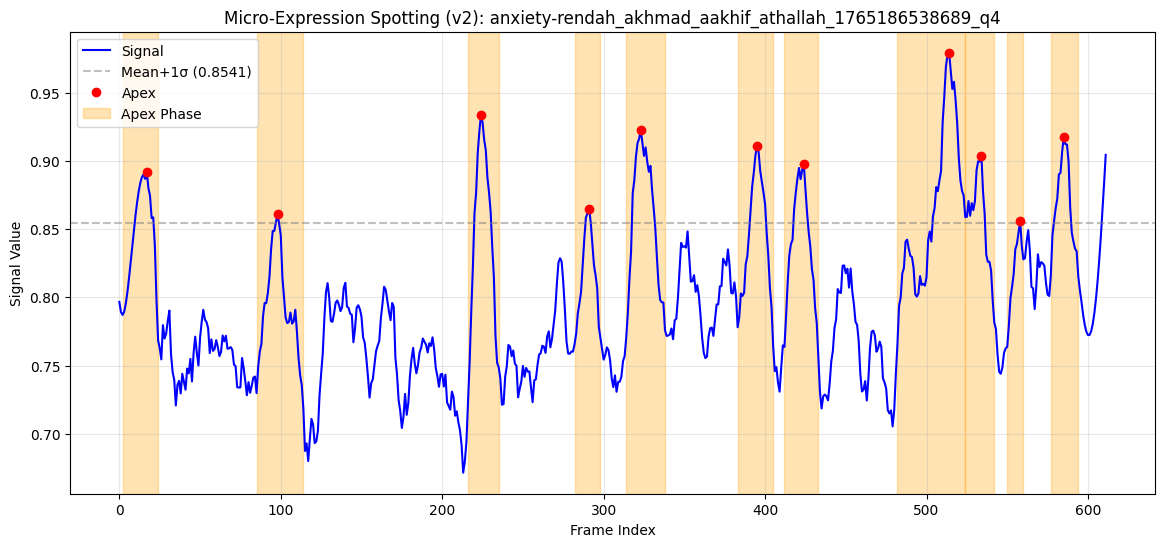

🔍 anxiety-rendah_akhmad_aakhif_athallah_1765186538689_q5 | frames=368 | window=19 | polyorder=4
  ✅ Apex: 11 | Onset: 4 | Offset: 21 | Duration: 17
  ✅ Apex: 44 | Onset: 39 | Offset: 49 | Duration: 10
  ✅ Apex: 54 | Onset: 50 | Offset: 59 | Duration: 9
  ✅ Apex: 73 | Onset: 68 | Offset: 78 | Duration: 10
  ✅ Apex: 92 | Onset: 82 | Offset: 99 | Duration: 17
  ✅ Apex: 110 | Onset: 102 | Offset: 124 | Duration: 22
  ✅ Apex: 145 | Onset: 138 | Offset: 154 | Duration: 16
  ✅ Apex: 189 | Onset: 180 | Offset: 200 | Duration: 20
  ✅ Apex: 236 | Onset: 230 | Offset: 241 | Duration: 11
  ✅ Apex: 268 | Onset: 253 | Offset: 273 | Duration: 20
  ✅ Apex: 280 | Onset: 276 | Offset: 286 | Duration: 10
  ✅ Apex: 314 | Onset: 306 | Offset: 318 | Duration: 12
  ✅ Apex: 356 | Onset: 350 | Offset: 362 | Duration: 12


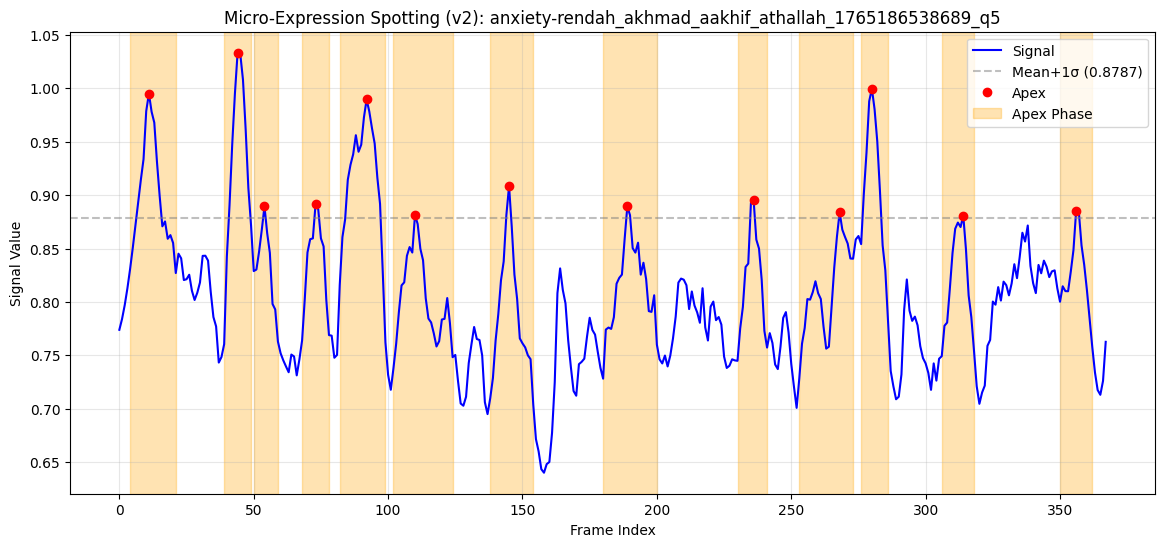

🔍 anxiety-rendah_haikal_muhammad_rafli_1765172380087_q1 | frames=755 | window=31 | polyorder=4
  ✅ Apex: 46 | Onset: 4 | Offset: 83 | Duration: 79
  ✅ Apex: 173 | Onset: 159 | Offset: 195 | Duration: 36
  ✅ Apex: 224 | Onset: 208 | Offset: 241 | Duration: 33
  ✅ Apex: 269 | Onset: 246 | Offset: 278 | Duration: 32
  ✅ Apex: 312 | Onset: 296 | Offset: 320 | Duration: 24
  ✅ Apex: 333 | Onset: 332 | Offset: 334 | Duration: 2
  ✅ Apex: 349 | Onset: 341 | Offset: 361 | Duration: 20
  ✅ Apex: 558 | Onset: 538 | Offset: 608 | Duration: 70
  ✅ Apex: 658 | Onset: 648 | Offset: 664 | Duration: 16
  ✅ Apex: 671 | Onset: 664 | Offset: 694 | Duration: 30
  ✅ Apex: 728 | Onset: 716 | Offset: 735 | Duration: 19
  ✅ Apex: 748 | Onset: 739 | Offset: 754 | Duration: 15


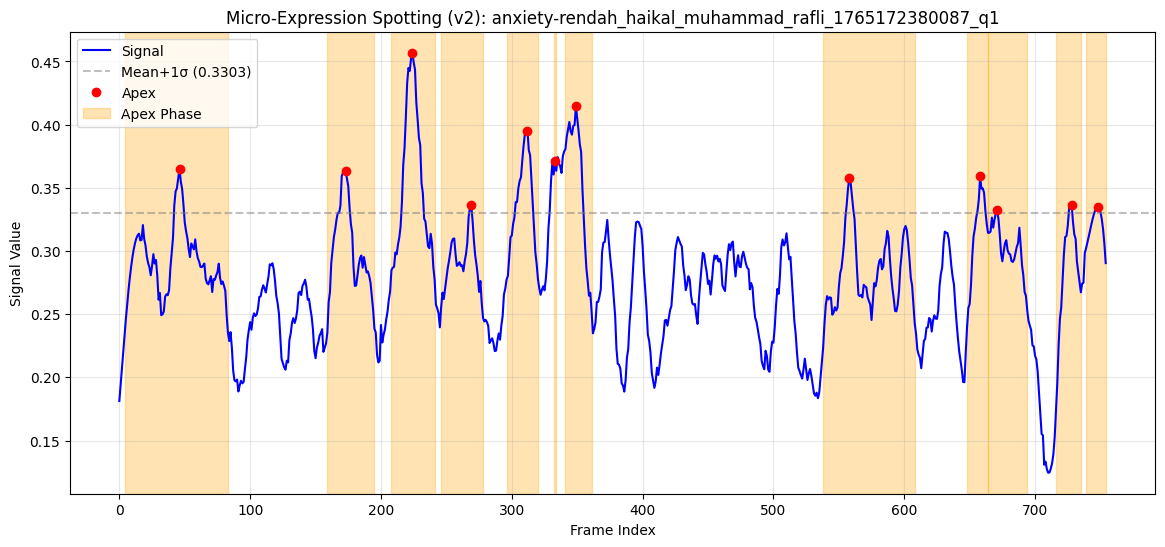

🔍 anxiety-rendah_haikal_muhammad_rafli_1765172380087_q2 | frames=408 | window=21 | polyorder=4
  ✅ Apex: 66 | Onset: 56 | Offset: 68 | Duration: 12
  ✅ Apex: 87 | Onset: 80 | Offset: 92 | Duration: 12
  ✅ Apex: 169 | Onset: 153 | Offset: 177 | Duration: 24
  ✅ Apex: 203 | Onset: 190 | Offset: 212 | Duration: 22
  ✅ Apex: 222 | Onset: 218 | Offset: 229 | Duration: 11
  ✅ Apex: 236 | Onset: 229 | Offset: 253 | Duration: 24
  ✅ Apex: 274 | Onset: 265 | Offset: 283 | Duration: 18
  ✅ Apex: 302 | Onset: 294 | Offset: 307 | Duration: 13
  ✅ Apex: 313 | Onset: 312 | Offset: 325 | Duration: 13
  ✅ Apex: 353 | Onset: 338 | Offset: 357 | Duration: 19
  ✅ Apex: 367 | Onset: 361 | Offset: 370 | Duration: 9
  ✅ Apex: 389 | Onset: 378 | Offset: 391 | Duration: 13
  ✅ Apex: 402 | Onset: 395 | Offset: 407 | Duration: 12


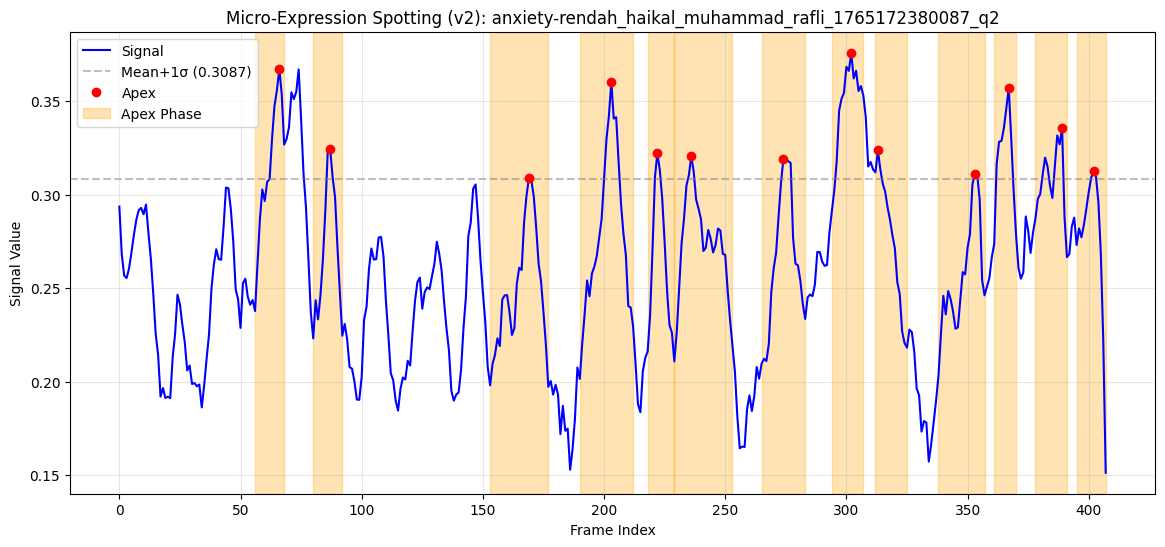

🔍 anxiety-rendah_haikal_muhammad_rafli_1765172380087_q3 | frames=649 | window=31 | polyorder=4
  ✅ Apex: 123 | Onset: 115 | Offset: 132 | Duration: 17
  ✅ Apex: 146 | Onset: 145 | Offset: 154 | Duration: 9
  ✅ Apex: 275 | Onset: 267 | Offset: 313 | Duration: 46
  ✅ Apex: 372 | Onset: 362 | Offset: 384 | Duration: 22
  ✅ Apex: 413 | Onset: 406 | Offset: 420 | Duration: 14
  ✅ Apex: 430 | Onset: 422 | Offset: 438 | Duration: 16
  ✅ Apex: 465 | Onset: 461 | Offset: 469 | Duration: 8
  ✅ Apex: 477 | Onset: 471 | Offset: 489 | Duration: 18
  ✅ Apex: 530 | Onset: 505 | Offset: 547 | Duration: 42
  ✅ Apex: 570 | Onset: 563 | Offset: 579 | Duration: 16
  ✅ Apex: 588 | Onset: 587 | Offset: 592 | Duration: 5
  ✅ Apex: 606 | Onset: 597 | Offset: 615 | Duration: 18
  ✅ Apex: 634 | Onset: 623 | Offset: 644 | Duration: 21


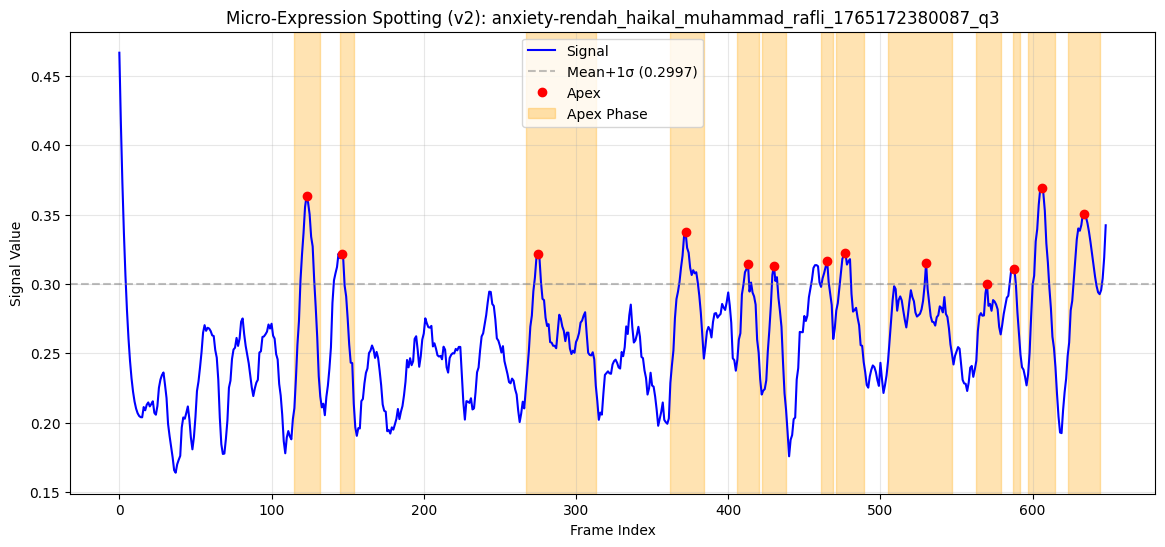

🔍 anxiety-rendah_haikal_muhammad_rafli_1765172380087_q4 | frames=406 | window=21 | polyorder=4
  ✅ Apex: 50 | Onset: 16 | Offset: 58 | Duration: 42
  ✅ Apex: 234 | Onset: 221 | Offset: 254 | Duration: 33
  ✅ Apex: 295 | Onset: 289 | Offset: 297 | Duration: 8
  ✅ Apex: 305 | Onset: 300 | Offset: 327 | Duration: 27


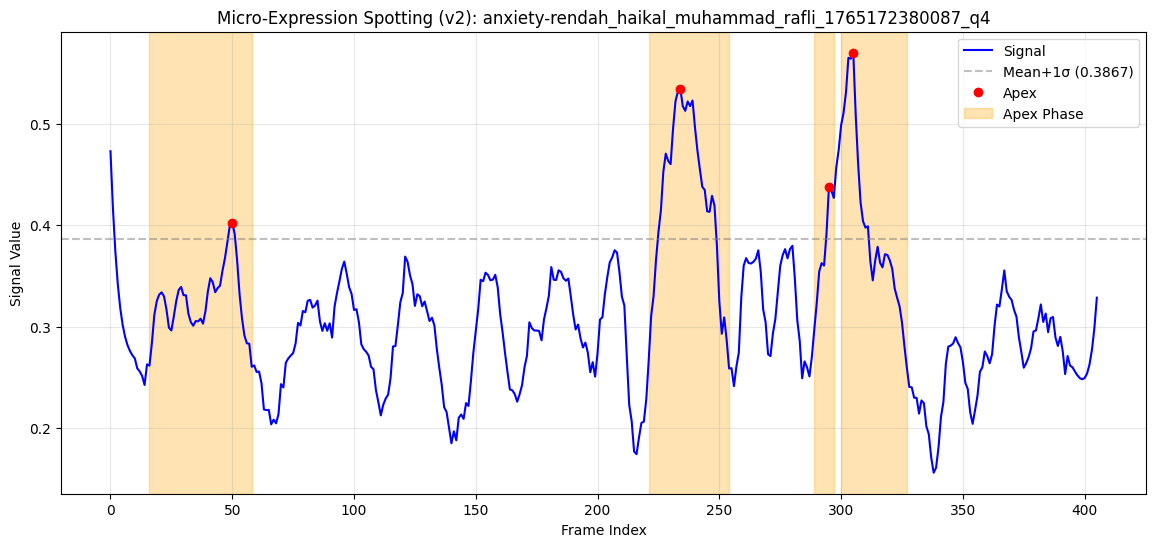

🔍 anxiety-rendah_haikal_muhammad_rafli_1765172380087_q5 | frames=225 | window=11 | polyorder=3
  ✅ Apex: 2 | Onset: 0 | Offset: 5 | Duration: 5
  ✅ Apex: 12 | Onset: 7 | Offset: 17 | Duration: 10
  ✅ Apex: 66 | Onset: 61 | Offset: 76 | Duration: 15
  ✅ Apex: 89 | Onset: 78 | Offset: 94 | Duration: 16
  ✅ Apex: 101 | Onset: 96 | Offset: 105 | Duration: 9
  ✅ Apex: 111 | Onset: 109 | Offset: 116 | Duration: 7
  ✅ Apex: 123 | Onset: 119 | Offset: 127 | Duration: 8
  ✅ Apex: 139 | Onset: 132 | Offset: 144 | Duration: 12
  ✅ Apex: 174 | Onset: 170 | Offset: 182 | Duration: 12
  ✅ Apex: 190 | Onset: 186 | Offset: 197 | Duration: 11
  ✅ Apex: 204 | Onset: 203 | Offset: 215 | Duration: 12


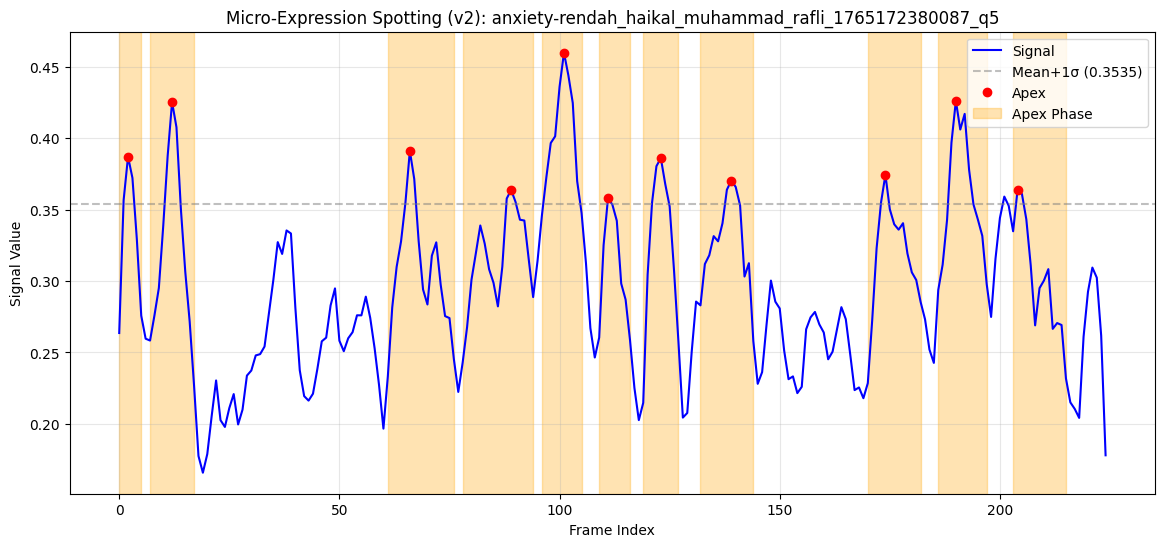

🔍 anxiety-rendah_hizkia_elsadanta_1765271523167_q1 | frames=543 | window=27 | polyorder=4
  ✅ Apex: 13 | Onset: 6 | Offset: 20 | Duration: 14
  ✅ Apex: 30 | Onset: 22 | Offset: 37 | Duration: 15
  ✅ Apex: 54 | Onset: 46 | Offset: 64 | Duration: 18
  ✅ Apex: 77 | Onset: 69 | Offset: 95 | Duration: 26
  ✅ Apex: 113 | Onset: 103 | Offset: 125 | Duration: 22
  ✅ Apex: 140 | Onset: 134 | Offset: 151 | Duration: 17
  ✅ Apex: 214 | Onset: 206 | Offset: 224 | Duration: 18
  ✅ Apex: 237 | Onset: 231 | Offset: 243 | Duration: 12
  ✅ Apex: 464 | Onset: 453 | Offset: 476 | Duration: 23
  ✅ Apex: 499 | Onset: 484 | Offset: 511 | Duration: 27
  ✅ Apex: 523 | Onset: 511 | Offset: 534 | Duration: 23


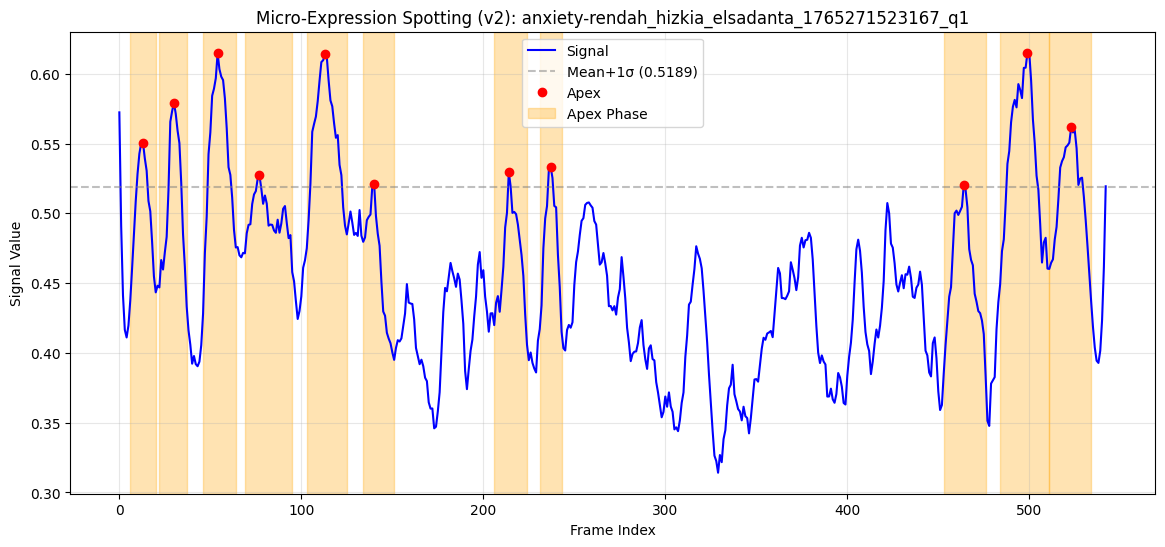

🔍 anxiety-rendah_hizkia_elsadanta_1765271523167_q2 | frames=262 | window=13 | polyorder=3
  ✅ Apex: 42 | Onset: 34 | Offset: 50 | Duration: 16
  ✅ Apex: 138 | Onset: 123 | Offset: 147 | Duration: 24
  ✅ Apex: 172 | Onset: 168 | Offset: 185 | Duration: 17
  ✅ Apex: 200 | Onset: 192 | Offset: 206 | Duration: 14
  ✅ Apex: 258 | Onset: 249 | Offset: 261 | Duration: 12


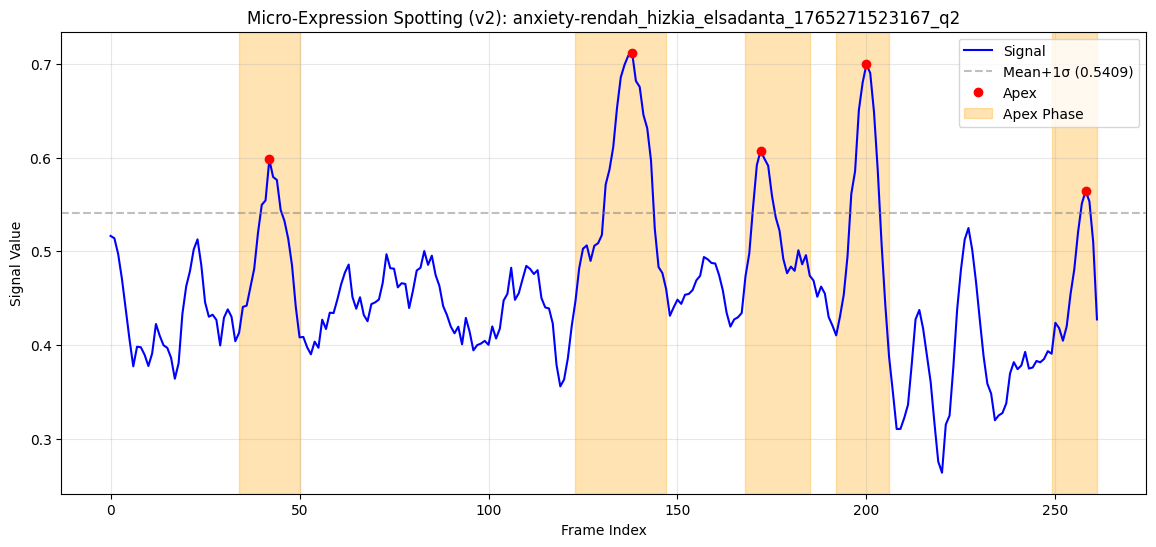

🔍 anxiety-rendah_hizkia_elsadanta_1765271523167_q3 | frames=263 | window=13 | polyorder=3
  ✅ Apex: 26 | Onset: 22 | Offset: 33 | Duration: 11
  ✅ Apex: 78 | Onset: 70 | Offset: 106 | Duration: 36
  ✅ Apex: 135 | Onset: 134 | Offset: 143 | Duration: 9
  ✅ Apex: 168 | Onset: 165 | Offset: 173 | Duration: 8
  ✅ Apex: 202 | Onset: 193 | Offset: 206 | Duration: 13
  ✅ Apex: 236 | Onset: 230 | Offset: 241 | Duration: 11


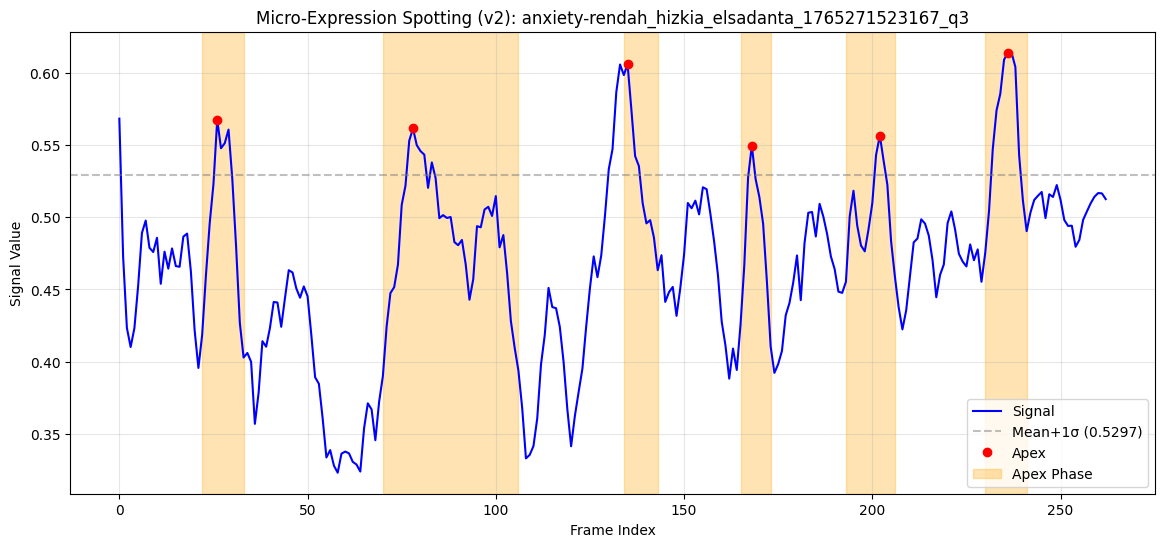

🔍 anxiety-rendah_hizkia_elsadanta_1765271523167_q4 | frames=730 | window=31 | polyorder=4
  ✅ Apex: 14 | Onset: 6 | Offset: 22 | Duration: 16
  ✅ Apex: 44 | Onset: 36 | Offset: 54 | Duration: 18
  ✅ Apex: 65 | Onset: 56 | Offset: 91 | Duration: 35
  ✅ Apex: 188 | Onset: 181 | Offset: 199 | Duration: 18
  ✅ Apex: 272 | Onset: 249 | Offset: 292 | Duration: 43
  ✅ Apex: 479 | Onset: 458 | Offset: 494 | Duration: 36
  ✅ Apex: 602 | Onset: 588 | Offset: 611 | Duration: 23
  ✅ Apex: 624 | Onset: 617 | Offset: 628 | Duration: 11
  ✅ Apex: 644 | Onset: 641 | Offset: 647 | Duration: 6
  ✅ Apex: 663 | Onset: 659 | Offset: 670 | Duration: 11
  ✅ Apex: 697 | Onset: 688 | Offset: 705 | Duration: 17
  ✅ Apex: 717 | Onset: 709 | Offset: 726 | Duration: 17


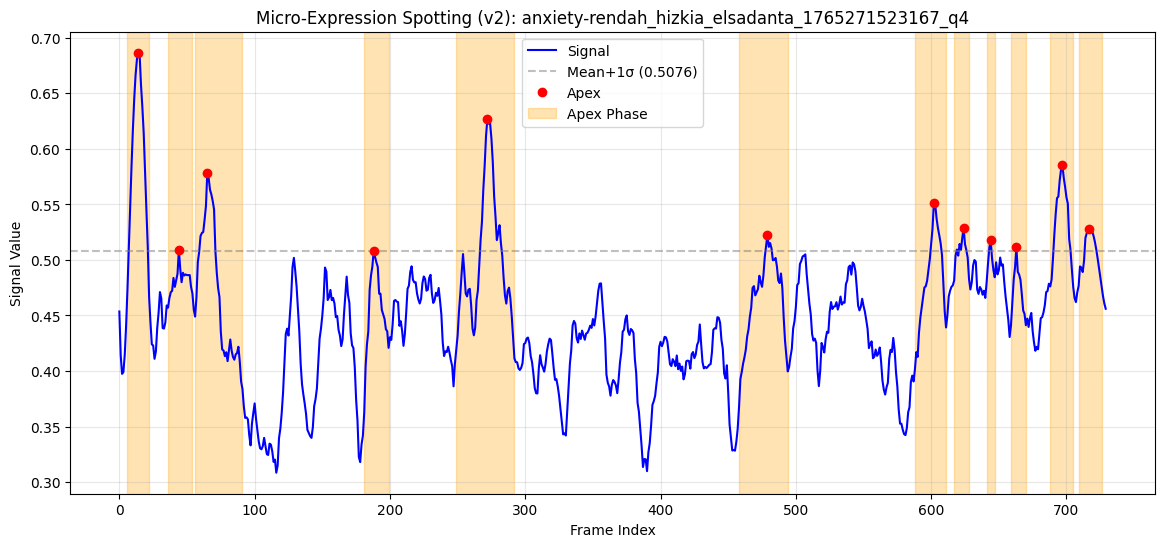

🔍 anxiety-rendah_hizkia_elsadanta_1765271523167_q5 | frames=329 | window=17 | polyorder=4
  ✅ Apex: 22 | Onset: 9 | Offset: 35 | Duration: 26
  ✅ Apex: 57 | Onset: 48 | Offset: 62 | Duration: 14
  ✅ Apex: 68 | Onset: 64 | Offset: 74 | Duration: 10
  ✅ Apex: 122 | Onset: 113 | Offset: 127 | Duration: 14
  ✅ Apex: 163 | Onset: 148 | Offset: 170 | Duration: 22
  ✅ Apex: 185 | Onset: 176 | Offset: 192 | Duration: 16
  ✅ Apex: 285 | Onset: 277 | Offset: 295 | Duration: 18
  ✅ Apex: 306 | Onset: 296 | Offset: 312 | Duration: 16
  ✅ Apex: 327 | Onset: 320 | Offset: 328 | Duration: 8


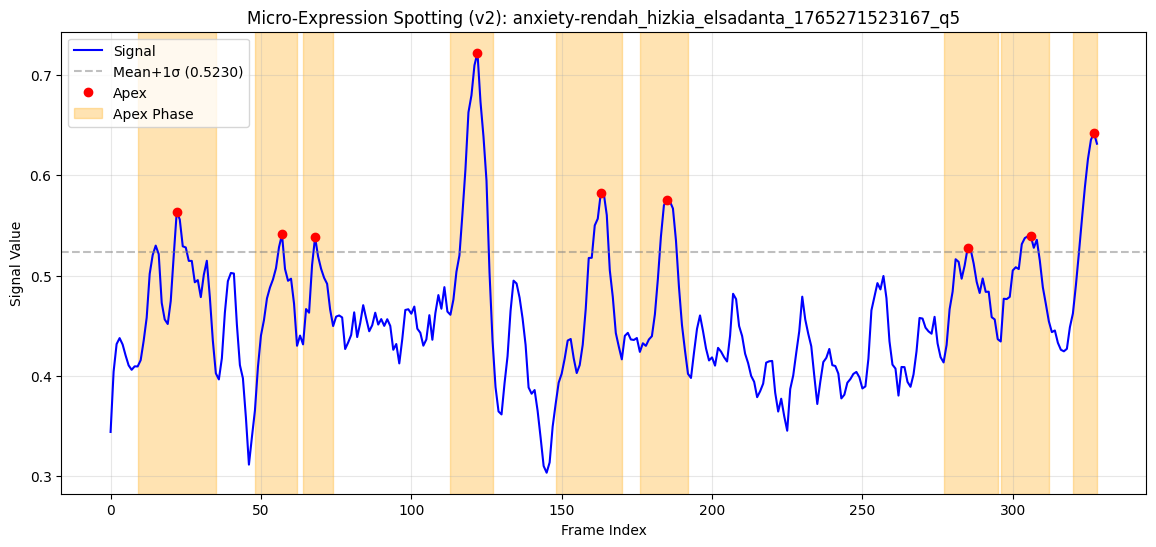

🔍 anxiety-rendah_key_firdausi_alfarel_1765179452414_q1 | frames=486 | window=25 | polyorder=4
  ✅ Apex: 53 | Onset: 46 | Offset: 60 | Duration: 14
  ✅ Apex: 175 | Onset: 168 | Offset: 181 | Duration: 13
  ✅ Apex: 187 | Onset: 184 | Offset: 194 | Duration: 10
  ✅ Apex: 273 | Onset: 266 | Offset: 284 | Duration: 18
  ✅ Apex: 344 | Onset: 332 | Offset: 355 | Duration: 23
  ✅ Apex: 418 | Onset: 405 | Offset: 429 | Duration: 24


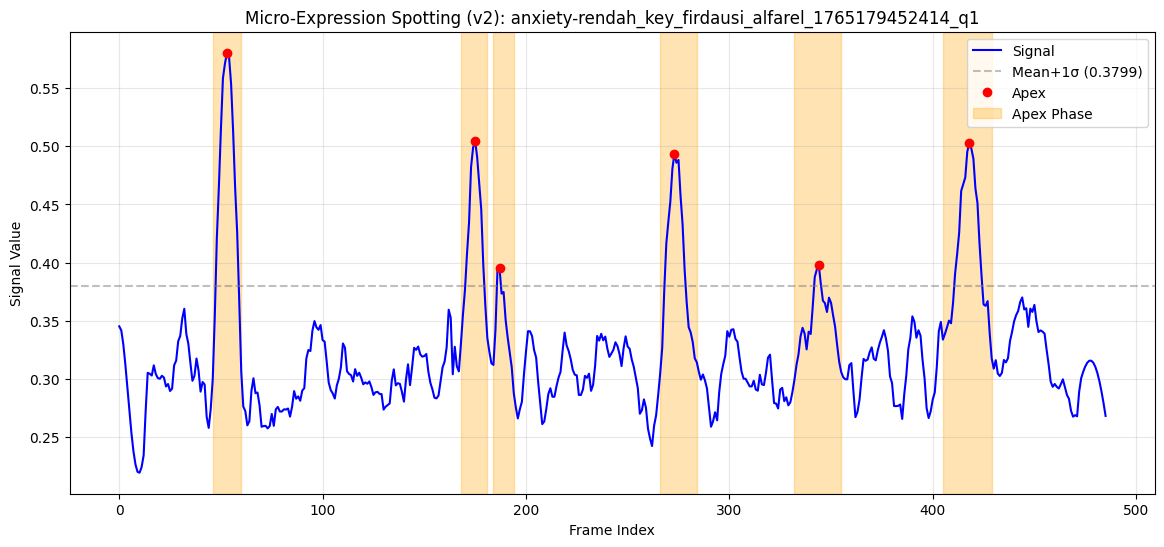

🔍 anxiety-rendah_key_firdausi_alfarel_1765179452414_q2 | frames=678 | window=31 | polyorder=4
  ✅ Apex: 57 | Onset: 42 | Offset: 82 | Duration: 40
  ✅ Apex: 115 | Onset: 102 | Offset: 127 | Duration: 25
  ✅ Apex: 216 | Onset: 191 | Offset: 235 | Duration: 44
  ✅ Apex: 341 | Onset: 330 | Offset: 349 | Duration: 19
  ✅ Apex: 357 | Onset: 352 | Offset: 362 | Duration: 10
  ✅ Apex: 375 | Onset: 366 | Offset: 382 | Duration: 16
  ✅ Apex: 398 | Onset: 389 | Offset: 412 | Duration: 23
  ✅ Apex: 431 | Onset: 422 | Offset: 434 | Duration: 12
  ✅ Apex: 445 | Onset: 438 | Offset: 458 | Duration: 20
  ✅ Apex: 578 | Onset: 555 | Offset: 589 | Duration: 34


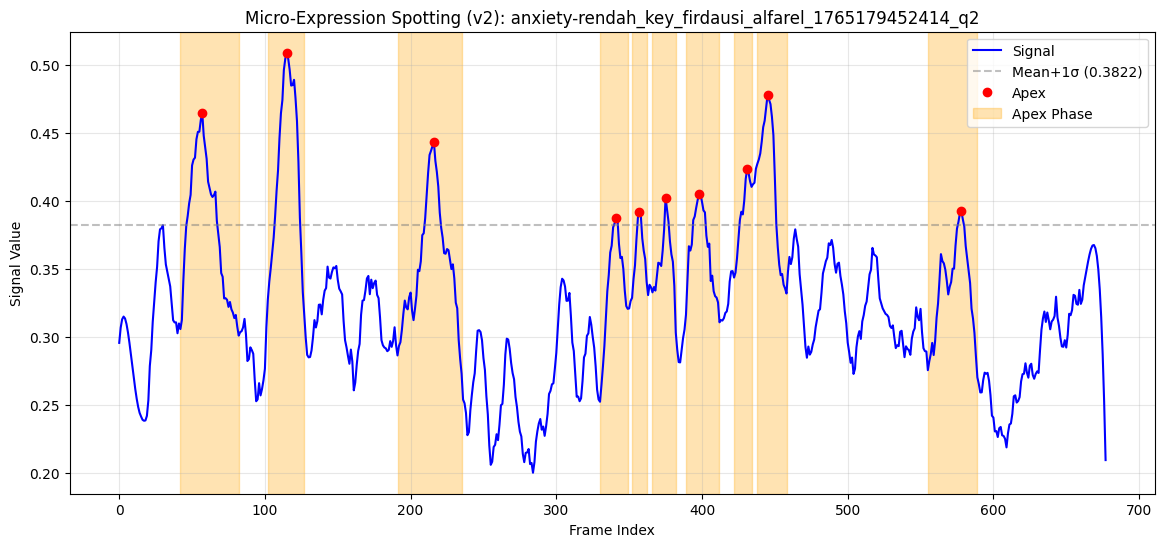

🔍 anxiety-rendah_key_firdausi_alfarel_1765179452414_q3 | frames=459 | window=23 | polyorder=4
  ✅ Apex: 11 | Onset: 3 | Offset: 19 | Duration: 16
  ✅ Apex: 154 | Onset: 146 | Offset: 160 | Duration: 14
  ✅ Apex: 275 | Onset: 267 | Offset: 293 | Duration: 26
  ✅ Apex: 314 | Onset: 307 | Offset: 320 | Duration: 13
  ✅ Apex: 343 | Onset: 337 | Offset: 349 | Duration: 12
  ✅ Apex: 397 | Onset: 388 | Offset: 421 | Duration: 33


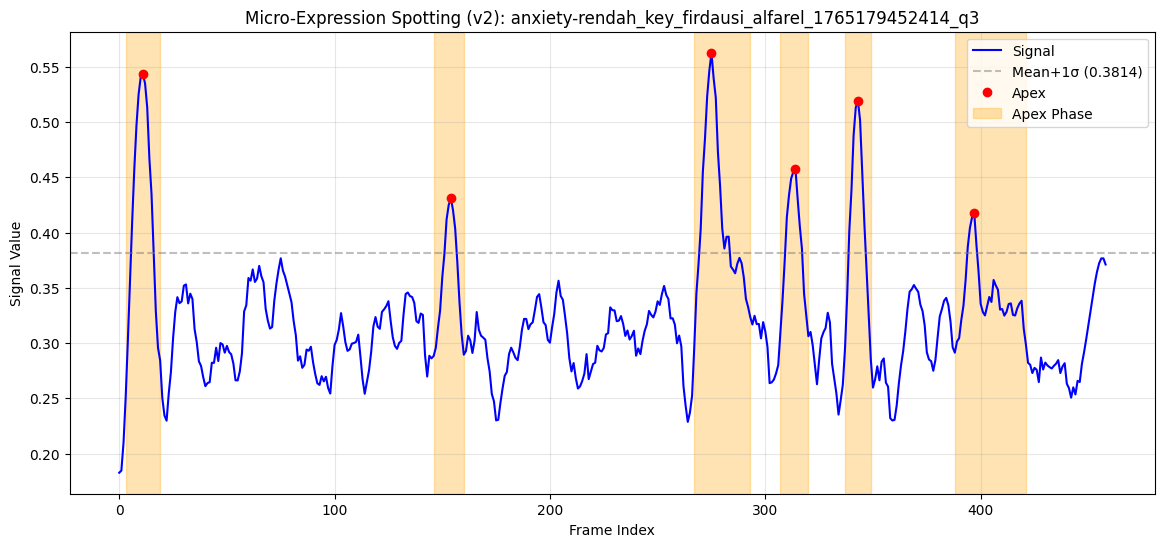

🔍 anxiety-rendah_key_firdausi_alfarel_1765179452414_q4 | frames=669 | window=31 | polyorder=4
  ✅ Apex: 4 | Onset: 0 | Offset: 10 | Duration: 10
  ✅ Apex: 19 | Onset: 15 | Offset: 26 | Duration: 11
  ✅ Apex: 41 | Onset: 30 | Offset: 54 | Duration: 24
  ✅ Apex: 100 | Onset: 88 | Offset: 111 | Duration: 23
  ✅ Apex: 165 | Onset: 154 | Offset: 175 | Duration: 21
  ✅ Apex: 237 | Onset: 230 | Offset: 247 | Duration: 17
  ✅ Apex: 279 | Onset: 273 | Offset: 291 | Duration: 18
  ✅ Apex: 386 | Onset: 377 | Offset: 391 | Duration: 14
  ✅ Apex: 402 | Onset: 395 | Offset: 409 | Duration: 14
  ✅ Apex: 472 | Onset: 463 | Offset: 483 | Duration: 20
  ✅ Apex: 502 | Onset: 492 | Offset: 512 | Duration: 20
  ✅ Apex: 534 | Onset: 525 | Offset: 543 | Duration: 18
  ✅ Apex: 608 | Onset: 601 | Offset: 618 | Duration: 17


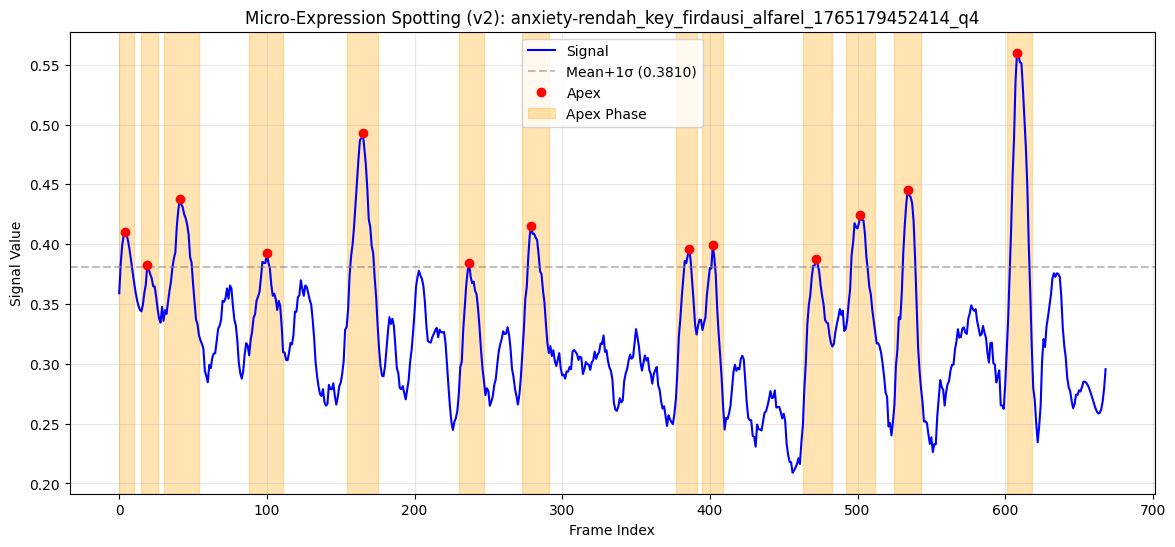

🔍 anxiety-rendah_key_firdausi_alfarel_1765179452414_q5 | frames=315 | window=15 | polyorder=3
  ✅ Apex: 22 | Onset: 14 | Offset: 29 | Duration: 15
  ✅ Apex: 95 | Onset: 93 | Offset: 104 | Duration: 11
  ✅ Apex: 189 | Onset: 184 | Offset: 197 | Duration: 13
  ✅ Apex: 309 | Onset: 302 | Offset: 314 | Duration: 12


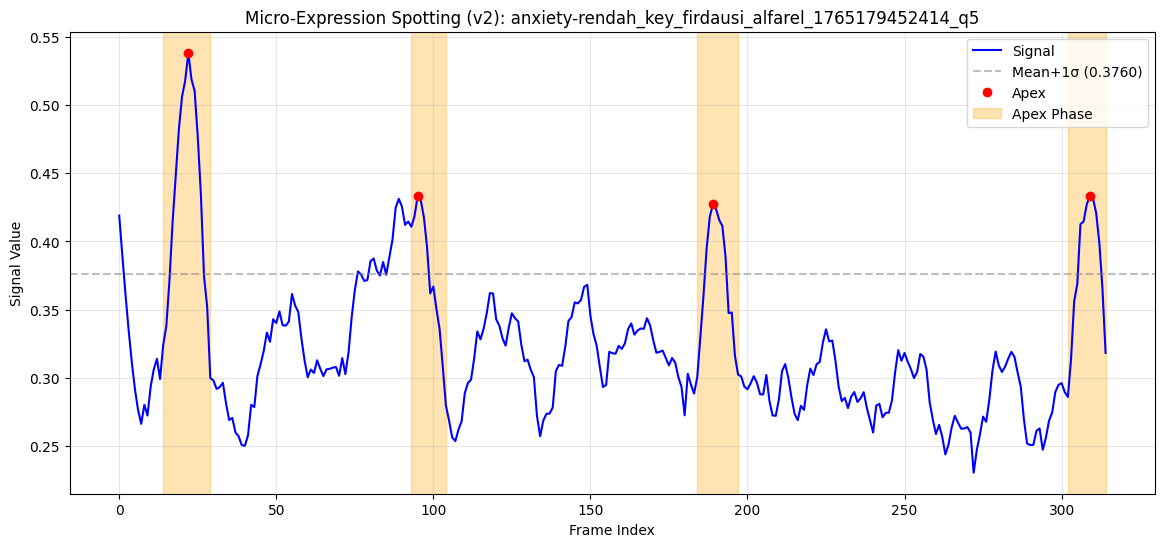

🔍 anxiety-tinggi_aaisyah_nursalsabiil_ni_patriarti_1765168488512_q1 | frames=622 | window=31 | polyorder=4
  ✅ Apex: 17 | Onset: 8 | Offset: 25 | Duration: 17
  ✅ Apex: 64 | Onset: 57 | Offset: 73 | Duration: 16
  ✅ Apex: 83 | Onset: 77 | Offset: 92 | Duration: 15
  ✅ Apex: 101 | Onset: 95 | Offset: 112 | Duration: 17
  ✅ Apex: 223 | Onset: 200 | Offset: 233 | Duration: 33
  ✅ Apex: 259 | Onset: 251 | Offset: 266 | Duration: 15
  ✅ Apex: 276 | Onset: 270 | Offset: 284 | Duration: 14
  ✅ Apex: 298 | Onset: 288 | Offset: 309 | Duration: 21
  ✅ Apex: 335 | Onset: 325 | Offset: 344 | Duration: 19
  ✅ Apex: 400 | Onset: 391 | Offset: 407 | Duration: 16
  ✅ Apex: 414 | Onset: 407 | Offset: 422 | Duration: 15
  ✅ Apex: 446 | Onset: 435 | Offset: 454 | Duration: 19
  ✅ Apex: 541 | Onset: 527 | Offset: 556 | Duration: 29


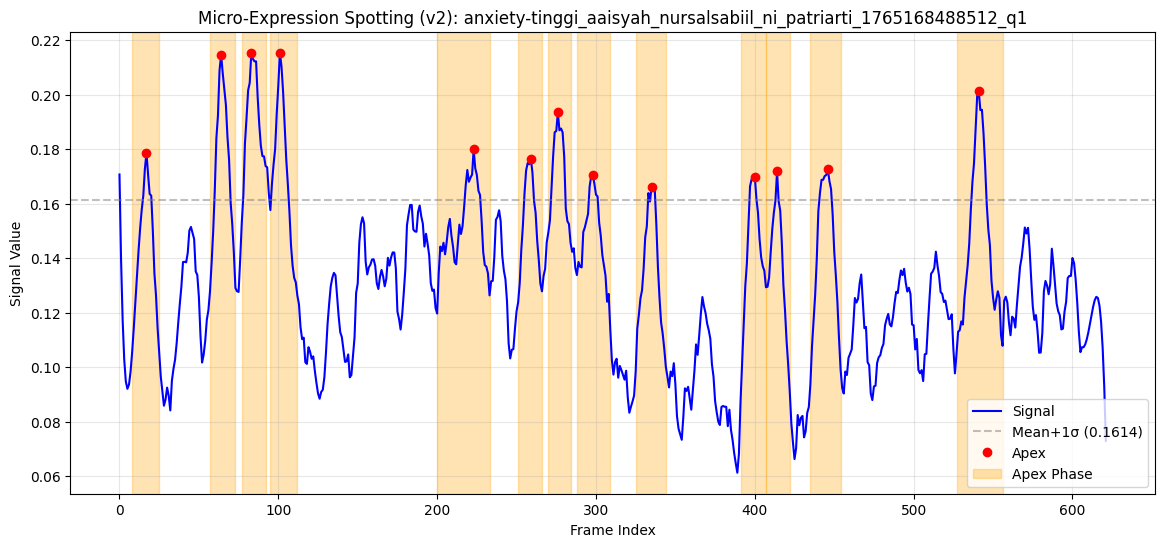

🔍 anxiety-tinggi_aaisyah_nursalsabiil_ni_patriarti_1765168488512_q2 | frames=597 | window=29 | polyorder=4
  ✅ Apex: 4 | Onset: 0 | Offset: 16 | Duration: 16
  ✅ Apex: 269 | Onset: 247 | Offset: 273 | Duration: 26
  ✅ Apex: 284 | Onset: 276 | Offset: 293 | Duration: 17
  ✅ Apex: 323 | Onset: 308 | Offset: 327 | Duration: 19
  ✅ Apex: 342 | Onset: 334 | Offset: 347 | Duration: 13
  ✅ Apex: 383 | Onset: 382 | Offset: 390 | Duration: 8
  ✅ Apex: 415 | Onset: 406 | Offset: 422 | Duration: 16
  ✅ Apex: 431 | Onset: 423 | Offset: 436 | Duration: 13
  ✅ Apex: 447 | Onset: 440 | Offset: 455 | Duration: 15
  ✅ Apex: 541 | Onset: 530 | Offset: 546 | Duration: 16
  ✅ Apex: 552 | Onset: 546 | Offset: 573 | Duration: 27


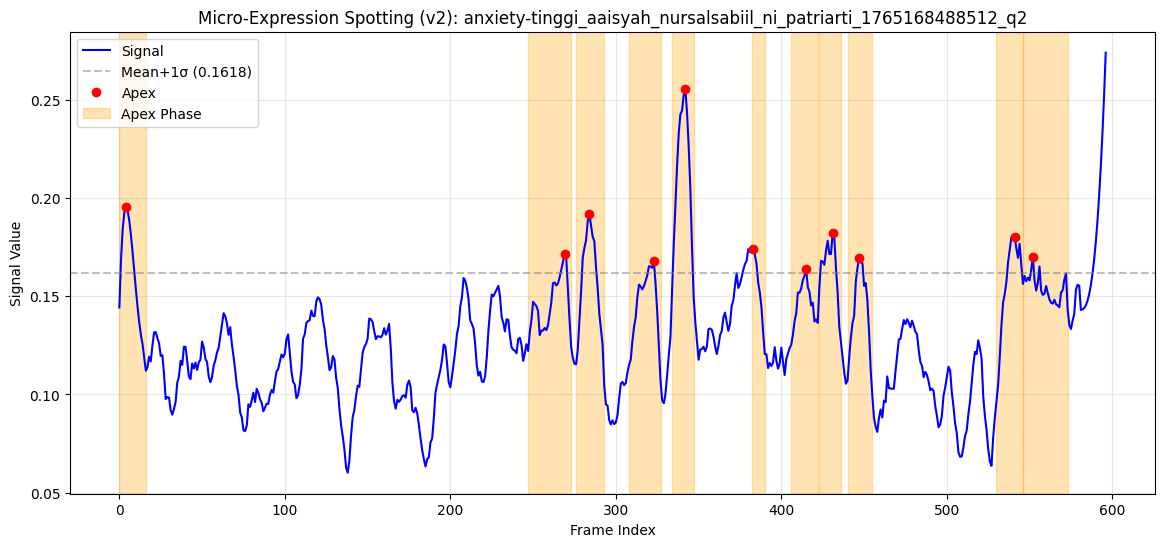

🔍 anxiety-tinggi_aaisyah_nursalsabiil_ni_patriarti_1765168488512_q3 | frames=472 | window=23 | polyorder=4
  ✅ Apex: 12 | Onset: 3 | Offset: 19 | Duration: 16
  ✅ Apex: 34 | Onset: 28 | Offset: 48 | Duration: 20
  ✅ Apex: 83 | Onset: 82 | Offset: 86 | Duration: 4
  ✅ Apex: 98 | Onset: 90 | Offset: 134 | Duration: 44
  ✅ Apex: 176 | Onset: 171 | Offset: 181 | Duration: 10
  ✅ Apex: 187 | Onset: 186 | Offset: 189 | Duration: 3
  ✅ Apex: 206 | Onset: 201 | Offset: 212 | Duration: 11
  ✅ Apex: 241 | Onset: 235 | Offset: 247 | Duration: 12
  ✅ Apex: 335 | Onset: 329 | Offset: 342 | Duration: 13
  ✅ Apex: 363 | Onset: 353 | Offset: 366 | Duration: 13
  ✅ Apex: 391 | Onset: 384 | Offset: 400 | Duration: 16
  ✅ Apex: 409 | Onset: 405 | Offset: 418 | Duration: 13
  ✅ Apex: 429 | Onset: 423 | Offset: 435 | Duration: 12
  ✅ Apex: 458 | Onset: 449 | Offset: 467 | Duration: 18


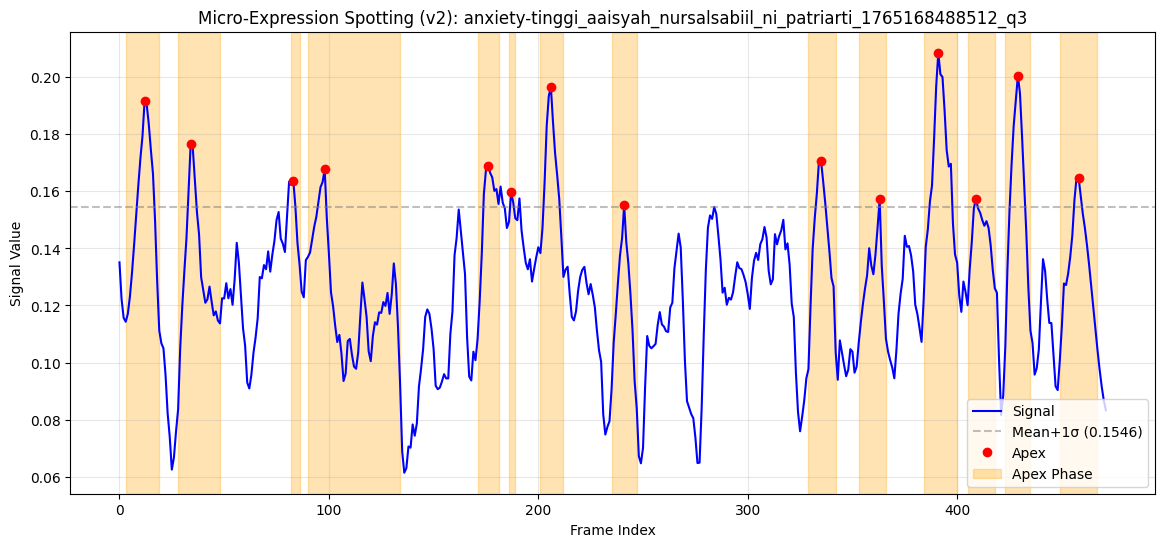

🔍 anxiety-tinggi_aaisyah_nursalsabiil_ni_patriarti_1765168488512_q4 | frames=701 | window=31 | polyorder=4
  ✅ Apex: 84 | Onset: 76 | Offset: 92 | Duration: 16
  ✅ Apex: 117 | Onset: 109 | Offset: 127 | Duration: 18
  ✅ Apex: 182 | Onset: 157 | Offset: 191 | Duration: 34
  ✅ Apex: 201 | Onset: 191 | Offset: 218 | Duration: 27
  ✅ Apex: 322 | Onset: 303 | Offset: 323 | Duration: 20
  ✅ Apex: 353 | Onset: 339 | Offset: 360 | Duration: 21
  ✅ Apex: 368 | Onset: 360 | Offset: 378 | Duration: 18
  ✅ Apex: 391 | Onset: 382 | Offset: 400 | Duration: 18
  ✅ Apex: 572 | Onset: 562 | Offset: 583 | Duration: 21
  ✅ Apex: 612 | Onset: 598 | Offset: 620 | Duration: 22
  ✅ Apex: 646 | Onset: 633 | Offset: 666 | Duration: 33


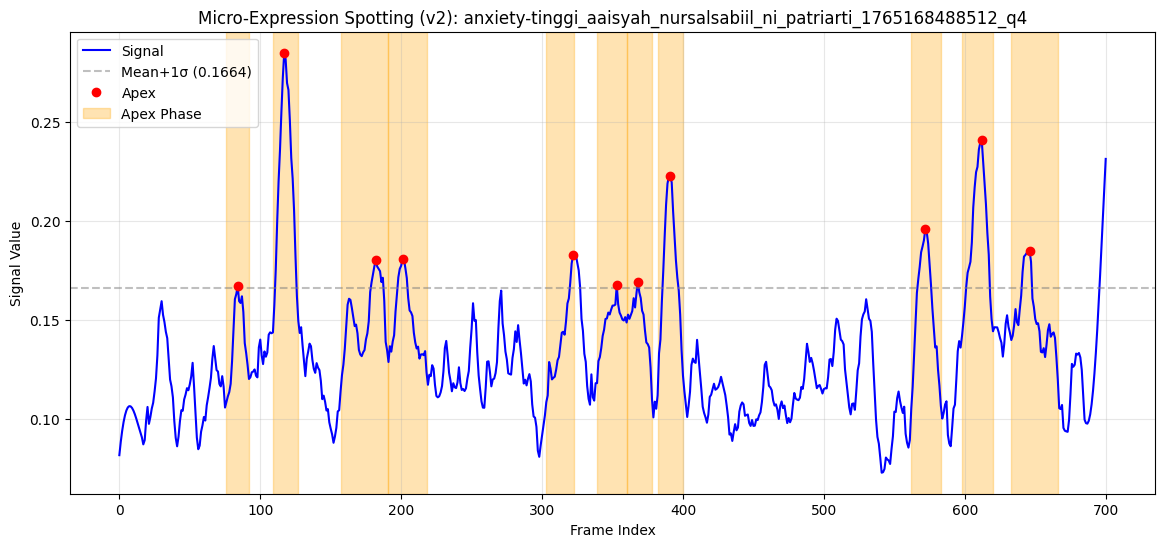

🔍 anxiety-tinggi_aaisyah_nursalsabiil_ni_patriarti_1765168488512_q5 | frames=546 | window=27 | polyorder=4
  ✅ Apex: 37 | Onset: 26 | Offset: 45 | Duration: 19
  ✅ Apex: 111 | Onset: 96 | Offset: 123 | Duration: 27
  ✅ Apex: 135 | Onset: 124 | Offset: 141 | Duration: 17
  ✅ Apex: 169 | Onset: 161 | Offset: 196 | Duration: 35
  ✅ Apex: 269 | Onset: 258 | Offset: 276 | Duration: 18
  ✅ Apex: 288 | Onset: 282 | Offset: 292 | Duration: 10
  ✅ Apex: 305 | Onset: 296 | Offset: 312 | Duration: 16
  ✅ Apex: 324 | Onset: 318 | Offset: 332 | Duration: 14
  ✅ Apex: 346 | Onset: 335 | Offset: 352 | Duration: 17
  ✅ Apex: 391 | Onset: 377 | Offset: 398 | Duration: 21


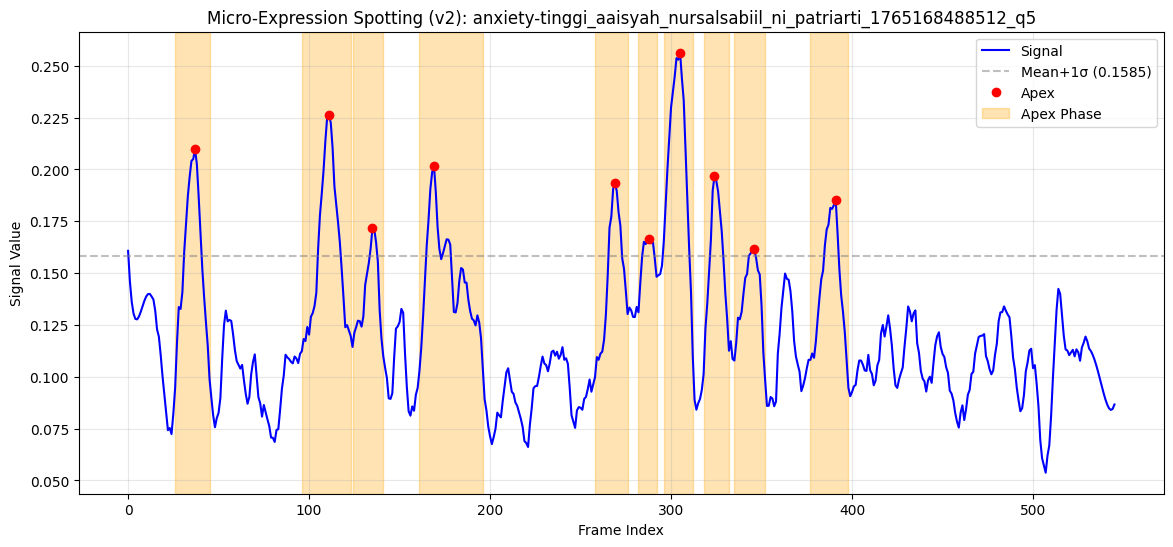

🔍 anxiety-tinggi_achmad_anfasa_rabbany_1765271116146_q1 | frames=847 | window=31 | polyorder=4
  ✅ Apex: 11 | Onset: 5 | Offset: 20 | Duration: 15
  ✅ Apex: 36 | Onset: 25 | Offset: 52 | Duration: 27
  ✅ Apex: 135 | Onset: 122 | Offset: 146 | Duration: 24
  ✅ Apex: 157 | Onset: 156 | Offset: 161 | Duration: 5
  ✅ Apex: 195 | Onset: 186 | Offset: 205 | Duration: 19
  ✅ Apex: 220 | Onset: 213 | Offset: 228 | Duration: 15
  ✅ Apex: 249 | Onset: 235 | Offset: 253 | Duration: 18
  ✅ Apex: 269 | Onset: 260 | Offset: 280 | Duration: 20
  ✅ Apex: 317 | Onset: 309 | Offset: 328 | Duration: 19
  ✅ Apex: 349 | Onset: 342 | Offset: 356 | Duration: 14
  ✅ Apex: 363 | Onset: 359 | Offset: 369 | Duration: 10
  ✅ Apex: 385 | Onset: 378 | Offset: 391 | Duration: 13
  ✅ Apex: 401 | Onset: 400 | Offset: 414 | Duration: 14
  ✅ Apex: 464 | Onset: 451 | Offset: 490 | Duration: 39


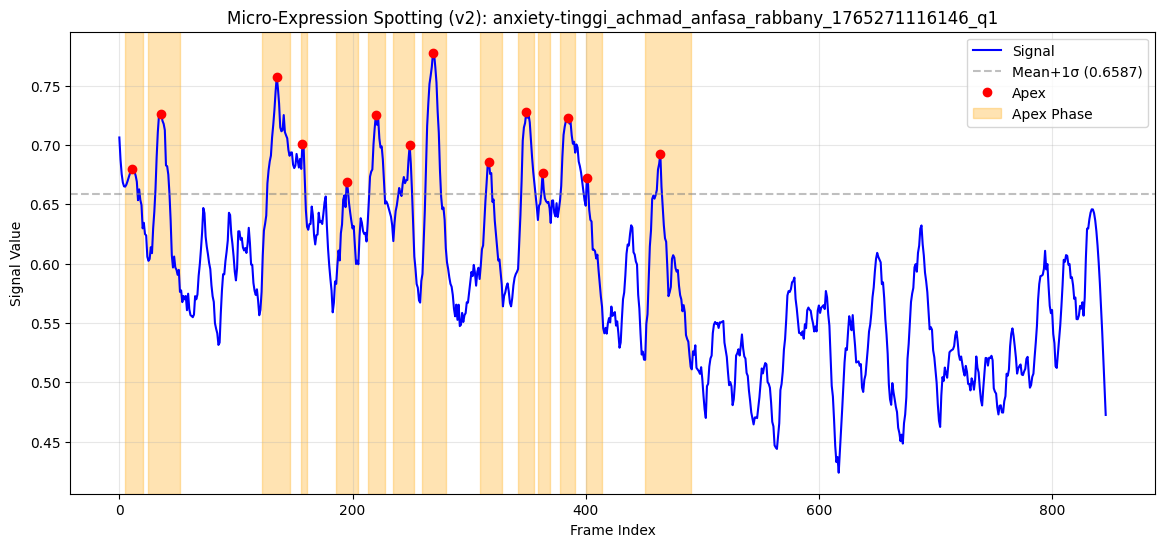

🔍 anxiety-tinggi_achmad_anfasa_rabbany_1765271116146_q2 | frames=284 | window=15 | polyorder=3
  ✅ Apex: 23 | Onset: 15 | Offset: 35 | Duration: 20
  ✅ Apex: 91 | Onset: 73 | Offset: 98 | Duration: 25
  ✅ Apex: 144 | Onset: 135 | Offset: 161 | Duration: 26
  ✅ Apex: 182 | Onset: 167 | Offset: 194 | Duration: 27
  ✅ Apex: 262 | Onset: 249 | Offset: 269 | Duration: 20


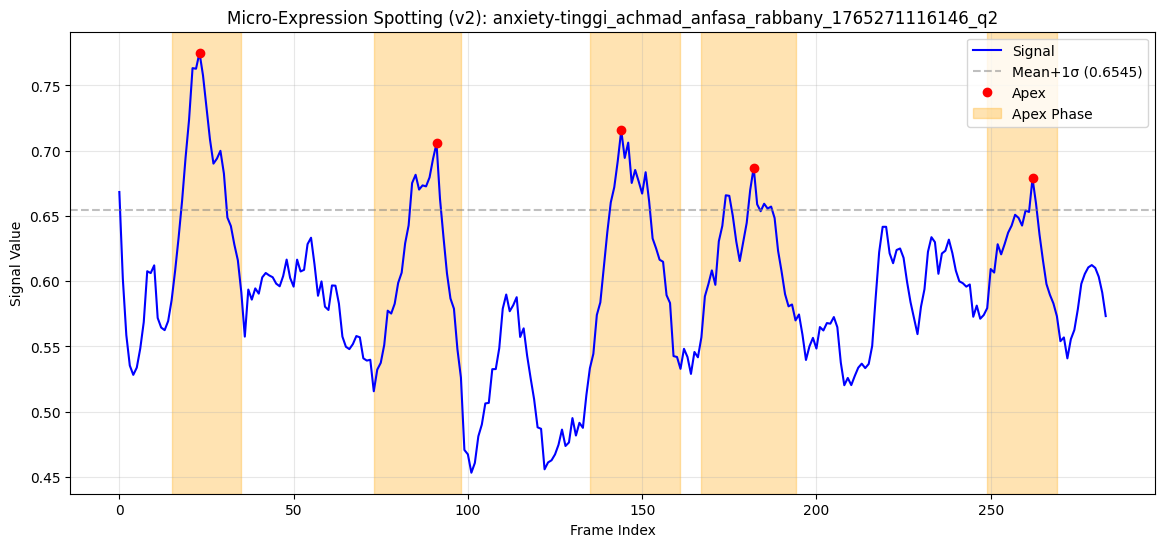

🔍 anxiety-tinggi_achmad_anfasa_rabbany_1765271116146_q3 | frames=369 | window=19 | polyorder=4
  ✅ Apex: 26 | Onset: 20 | Offset: 31 | Duration: 11
  ✅ Apex: 76 | Onset: 69 | Offset: 82 | Duration: 13
  ✅ Apex: 91 | Onset: 86 | Offset: 97 | Duration: 11
  ✅ Apex: 105 | Onset: 100 | Offset: 118 | Duration: 18
  ✅ Apex: 170 | Onset: 145 | Offset: 175 | Duration: 30
  ✅ Apex: 181 | Onset: 175 | Offset: 186 | Duration: 11
  ✅ Apex: 195 | Onset: 190 | Offset: 200 | Duration: 10
  ✅ Apex: 222 | Onset: 215 | Offset: 226 | Duration: 11
  ✅ Apex: 233 | Onset: 228 | Offset: 237 | Duration: 9
  ✅ Apex: 291 | Onset: 285 | Offset: 298 | Duration: 13
  ✅ Apex: 337 | Onset: 334 | Offset: 343 | Duration: 9


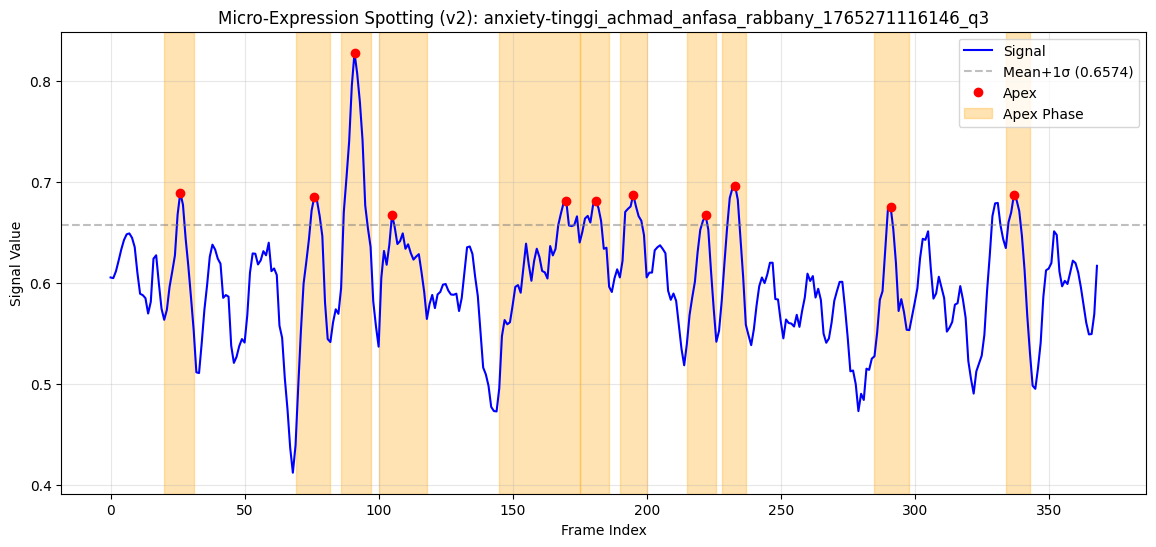

🔍 anxiety-tinggi_achmad_anfasa_rabbany_1765271116146_q4 | frames=199 | window=9 | polyorder=3
  ✅ Apex: 46 | Onset: 42 | Offset: 49 | Duration: 7
  ✅ Apex: 69 | Onset: 58 | Offset: 77 | Duration: 19
  ✅ Apex: 90 | Onset: 84 | Offset: 95 | Duration: 11
  ✅ Apex: 113 | Onset: 108 | Offset: 117 | Duration: 9
  ✅ Apex: 140 | Onset: 134 | Offset: 145 | Duration: 11
  ✅ Apex: 151 | Onset: 146 | Offset: 157 | Duration: 11
  ✅ Apex: 178 | Onset: 173 | Offset: 187 | Duration: 14
  ✅ Apex: 196 | Onset: 192 | Offset: 198 | Duration: 6


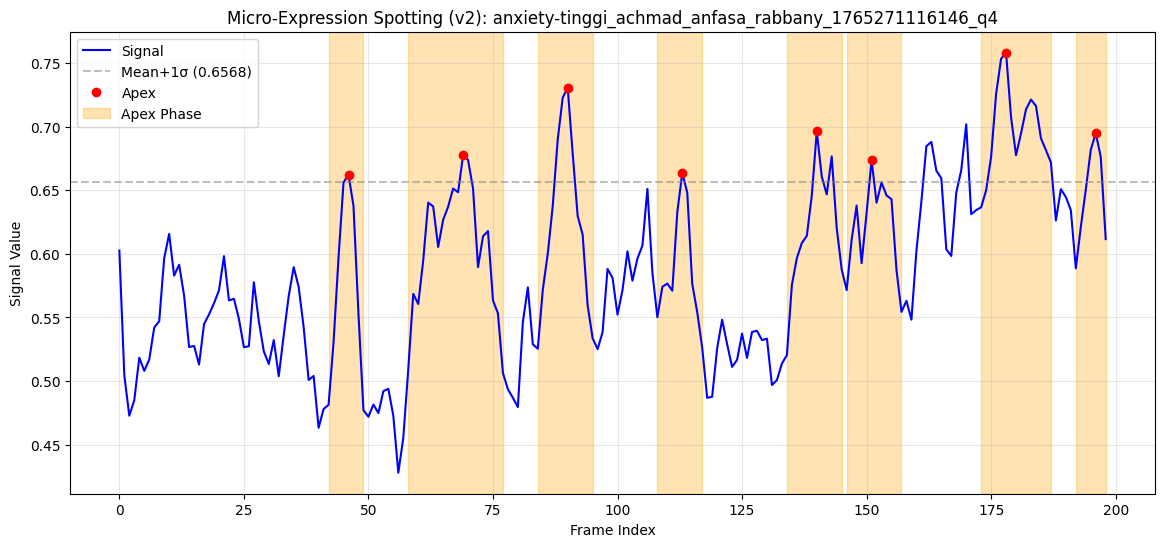

🔍 anxiety-tinggi_achmad_anfasa_rabbany_1765271116146_q5 | frames=295 | window=15 | polyorder=3
  ✅ Apex: 6 | Onset: 1 | Offset: 15 | Duration: 14
  ✅ Apex: 69 | Onset: 61 | Offset: 74 | Duration: 13
  ✅ Apex: 80 | Onset: 75 | Offset: 88 | Duration: 13
  ✅ Apex: 109 | Onset: 107 | Offset: 112 | Duration: 5
  ✅ Apex: 165 | Onset: 160 | Offset: 168 | Duration: 8
  ✅ Apex: 230 | Onset: 229 | Offset: 241 | Duration: 12
  ✅ Apex: 252 | Onset: 243 | Offset: 259 | Duration: 16


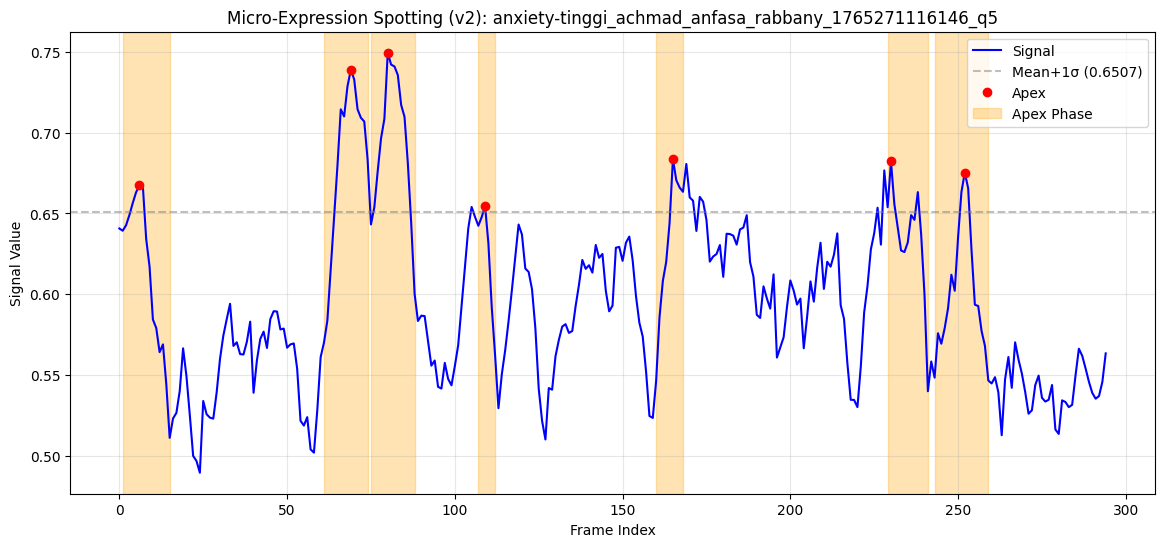

🔍 anxiety-tinggi_dika_arie_arrifky_1765264792036_q1 | frames=1045 | window=31 | polyorder=4
  ✅ Apex: 53 | Onset: 38 | Offset: 54 | Duration: 16
  ✅ Apex: 93 | Onset: 80 | Offset: 102 | Duration: 22
  ✅ Apex: 141 | Onset: 129 | Offset: 151 | Duration: 22
  ✅ Apex: 162 | Onset: 155 | Offset: 172 | Duration: 17
  ✅ Apex: 257 | Onset: 243 | Offset: 267 | Duration: 24
  ✅ Apex: 334 | Onset: 325 | Offset: 342 | Duration: 17
  ✅ Apex: 378 | Onset: 370 | Offset: 385 | Duration: 15
  ✅ Apex: 420 | Onset: 412 | Offset: 430 | Duration: 18
  ✅ Apex: 444 | Onset: 435 | Offset: 450 | Duration: 15
  ✅ Apex: 472 | Onset: 461 | Offset: 478 | Duration: 17
  ✅ Apex: 489 | Onset: 480 | Offset: 497 | Duration: 17
  ✅ Apex: 627 | Onset: 618 | Offset: 648 | Duration: 30
  ✅ Apex: 745 | Onset: 728 | Offset: 761 | Duration: 33
  ✅ Apex: 783 | Onset: 764 | Offset: 799 | Duration: 35
  ✅ Apex: 837 | Onset: 823 | Offset: 871 | Duration: 48
  ✅ Apex: 908 | Onset: 872 | Offset: 922 | Duration: 50
  ✅ Apex: 1003 | 

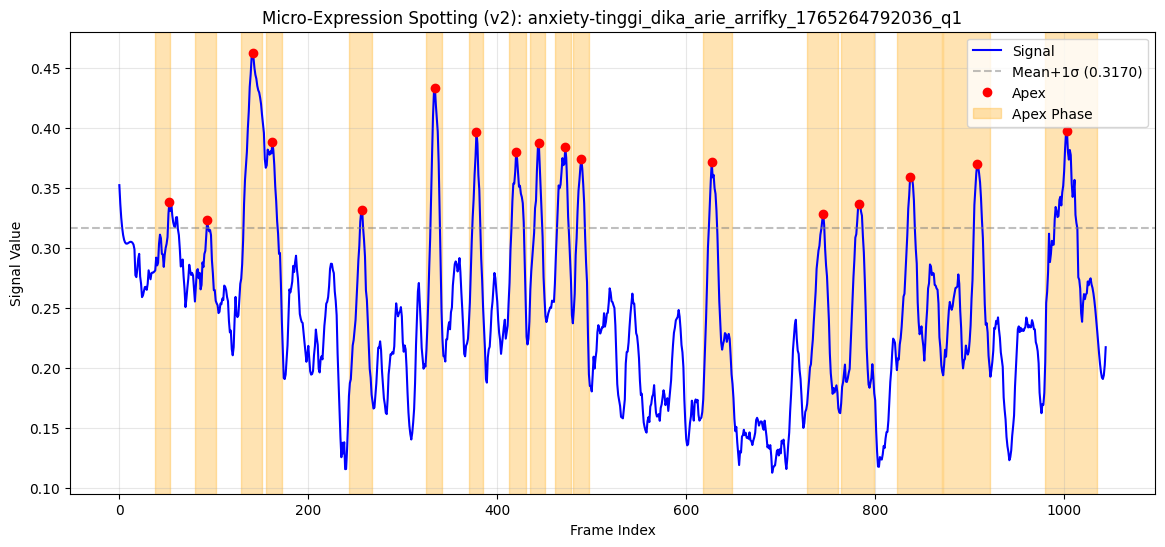

🔍 anxiety-tinggi_dika_arie_arrifky_1765264792036_q2 | frames=746 | window=31 | polyorder=4
  ✅ Apex: 31 | Onset: 11 | Offset: 41 | Duration: 30
  ✅ Apex: 85 | Onset: 78 | Offset: 96 | Duration: 18
  ✅ Apex: 115 | Onset: 107 | Offset: 125 | Duration: 18
  ✅ Apex: 179 | Onset: 169 | Offset: 189 | Duration: 20
  ✅ Apex: 199 | Onset: 198 | Offset: 210 | Duration: 12
  ✅ Apex: 366 | Onset: 356 | Offset: 379 | Duration: 23
  ✅ Apex: 538 | Onset: 496 | Offset: 543 | Duration: 47
  ✅ Apex: 551 | Onset: 546 | Offset: 558 | Duration: 12
  ✅ Apex: 568 | Onset: 560 | Offset: 589 | Duration: 29
  ✅ Apex: 635 | Onset: 627 | Offset: 642 | Duration: 15
  ✅ Apex: 652 | Onset: 643 | Offset: 661 | Duration: 18
  ✅ Apex: 679 | Onset: 672 | Offset: 682 | Duration: 10
  ✅ Apex: 690 | Onset: 688 | Offset: 693 | Duration: 5
  ✅ Apex: 705 | Onset: 701 | Offset: 710 | Duration: 9
  ✅ Apex: 724 | Onset: 715 | Offset: 744 | Duration: 29


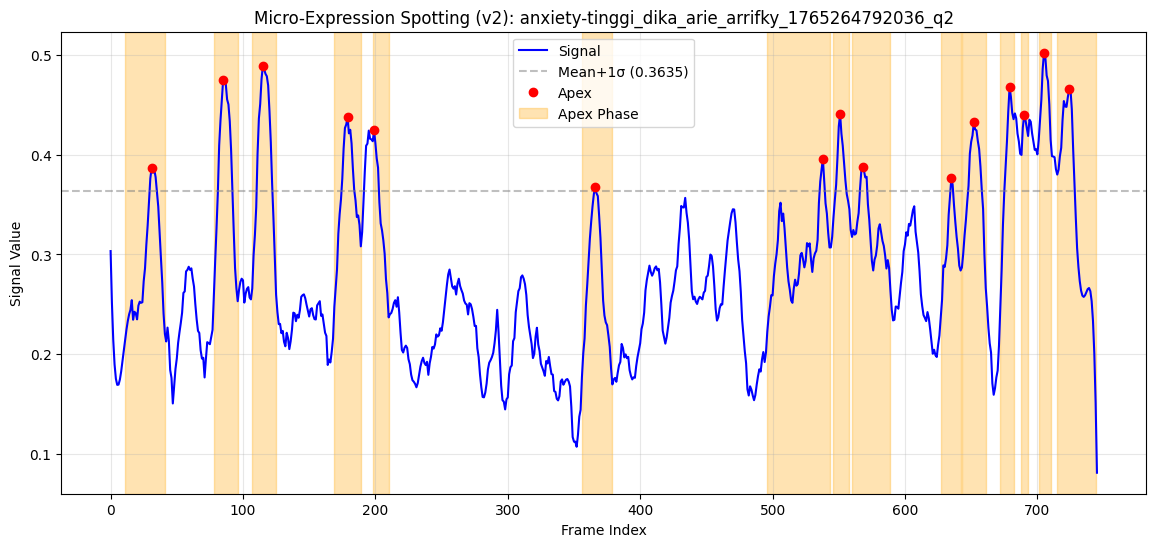

🔍 anxiety-tinggi_dika_arie_arrifky_1765264792036_q3 | frames=399 | window=19 | polyorder=4
  ✅ Apex: 121 | Onset: 115 | Offset: 126 | Duration: 11
  ✅ Apex: 190 | Onset: 171 | Offset: 196 | Duration: 25
  ✅ Apex: 205 | Onset: 198 | Offset: 214 | Duration: 16
  ✅ Apex: 249 | Onset: 243 | Offset: 252 | Duration: 9
  ✅ Apex: 263 | Onset: 258 | Offset: 270 | Duration: 12
  ✅ Apex: 283 | Onset: 276 | Offset: 289 | Duration: 13
  ✅ Apex: 296 | Onset: 293 | Offset: 298 | Duration: 5
  ✅ Apex: 310 | Onset: 305 | Offset: 319 | Duration: 14
  ✅ Apex: 328 | Onset: 325 | Offset: 336 | Duration: 11
  ✅ Apex: 351 | Onset: 344 | Offset: 360 | Duration: 16


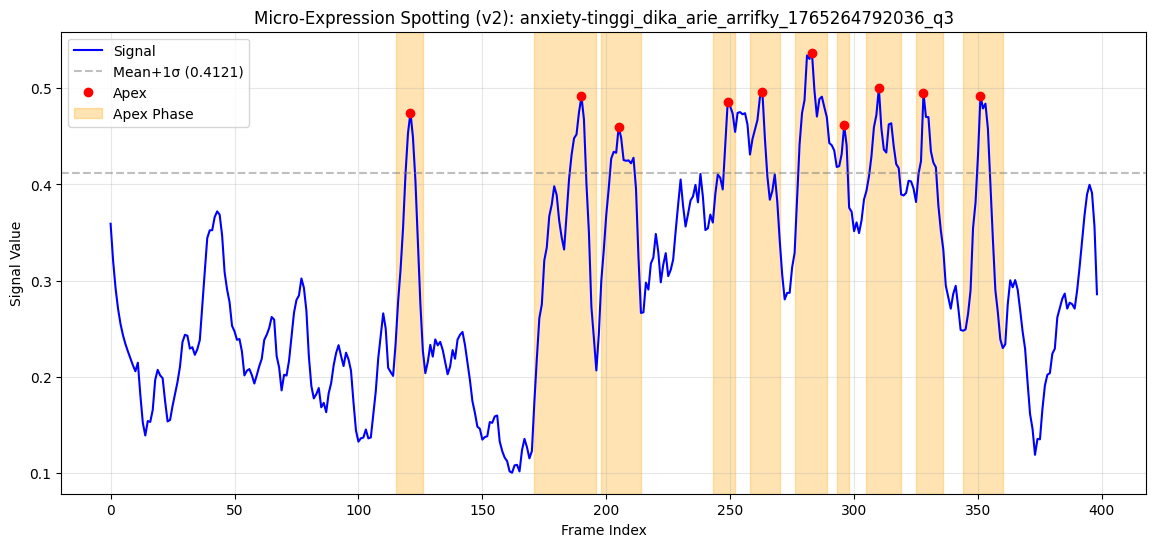

🔍 anxiety-tinggi_dika_arie_arrifky_1765264792036_q4 | frames=326 | window=17 | polyorder=4
  ✅ Apex: 10 | Onset: 5 | Offset: 16 | Duration: 11
  ✅ Apex: 46 | Onset: 39 | Offset: 54 | Duration: 15
  ✅ Apex: 62 | Onset: 56 | Offset: 69 | Duration: 13
  ✅ Apex: 172 | Onset: 166 | Offset: 176 | Duration: 10
  ✅ Apex: 201 | Onset: 192 | Offset: 208 | Duration: 16
  ✅ Apex: 217 | Onset: 213 | Offset: 221 | Duration: 8
  ✅ Apex: 297 | Onset: 285 | Offset: 321 | Duration: 36


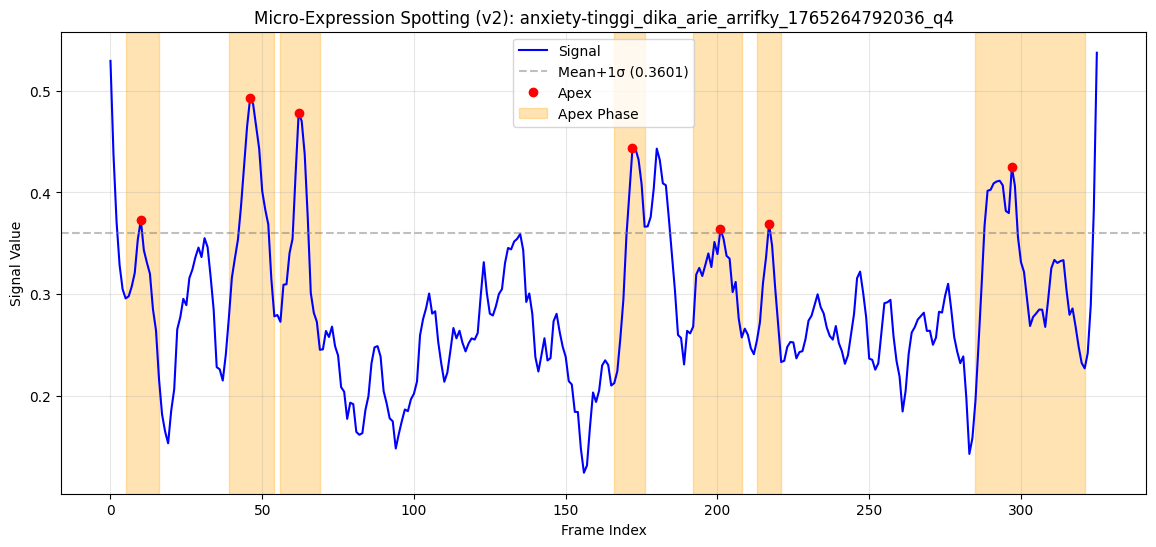

🔍 anxiety-tinggi_dika_arie_arrifky_1765264792036_q5 | frames=302 | window=15 | polyorder=3
  ✅ Apex: 15 | Onset: 8 | Offset: 20 | Duration: 12
  ✅ Apex: 31 | Onset: 23 | Offset: 38 | Duration: 15
  ✅ Apex: 60 | Onset: 49 | Offset: 70 | Duration: 21
  ✅ Apex: 193 | Onset: 185 | Offset: 202 | Duration: 17
  ✅ Apex: 212 | Onset: 204 | Offset: 218 | Duration: 14
  ✅ Apex: 235 | Onset: 224 | Offset: 244 | Duration: 20
  ✅ Apex: 269 | Onset: 254 | Offset: 274 | Duration: 20


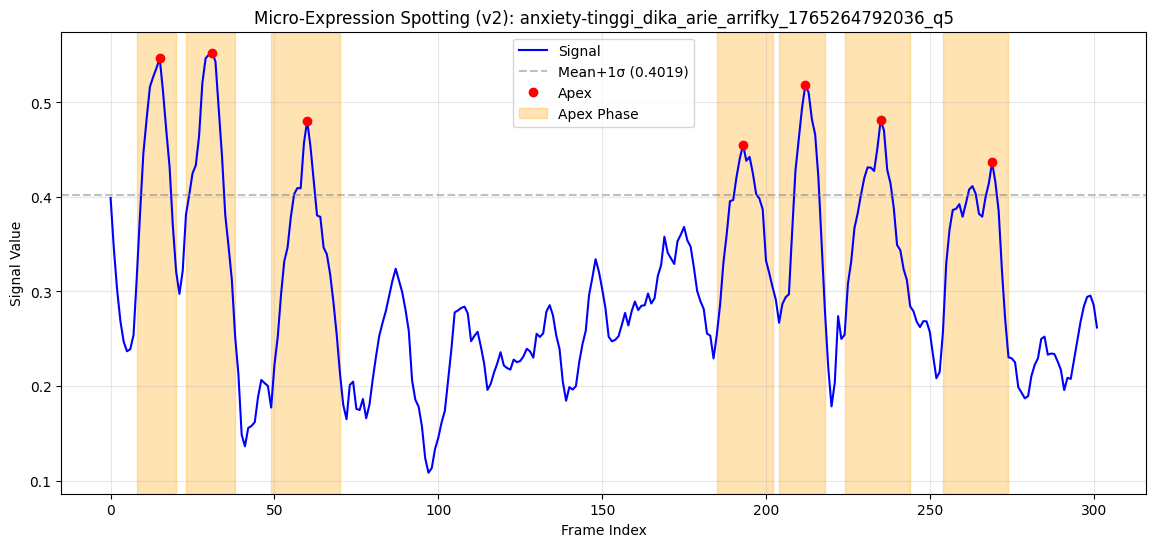

🔍 anxiety-tinggi_fabian_ananda_merdana_1765255189409_q1 | frames=1047 | window=31 | polyorder=4
  ✅ Apex: 16 | Onset: 9 | Offset: 22 | Duration: 13
  ✅ Apex: 33 | Onset: 30 | Offset: 37 | Duration: 7
  ✅ Apex: 45 | Onset: 44 | Offset: 50 | Duration: 6
  ✅ Apex: 76 | Onset: 62 | Offset: 85 | Duration: 23
  ✅ Apex: 122 | Onset: 111 | Offset: 129 | Duration: 18
  ✅ Apex: 136 | Onset: 132 | Offset: 147 | Duration: 15
  ✅ Apex: 171 | Onset: 158 | Offset: 181 | Duration: 23
  ✅ Apex: 395 | Onset: 360 | Offset: 422 | Duration: 62
  ✅ Apex: 449 | Onset: 434 | Offset: 460 | Duration: 26
  ✅ Apex: 508 | Onset: 499 | Offset: 520 | Duration: 21
  ✅ Apex: 538 | Onset: 529 | Offset: 545 | Duration: 16
  ✅ Apex: 555 | Onset: 546 | Offset: 567 | Duration: 21
  ✅ Apex: 882 | Onset: 867 | Offset: 893 | Duration: 26
  ✅ Apex: 904 | Onset: 896 | Offset: 913 | Duration: 17
  ✅ Apex: 955 | Onset: 949 | Offset: 963 | Duration: 14
  ✅ Apex: 996 | Onset: 987 | Offset: 1007 | Duration: 20
  ✅ Apex: 1029 | Onset

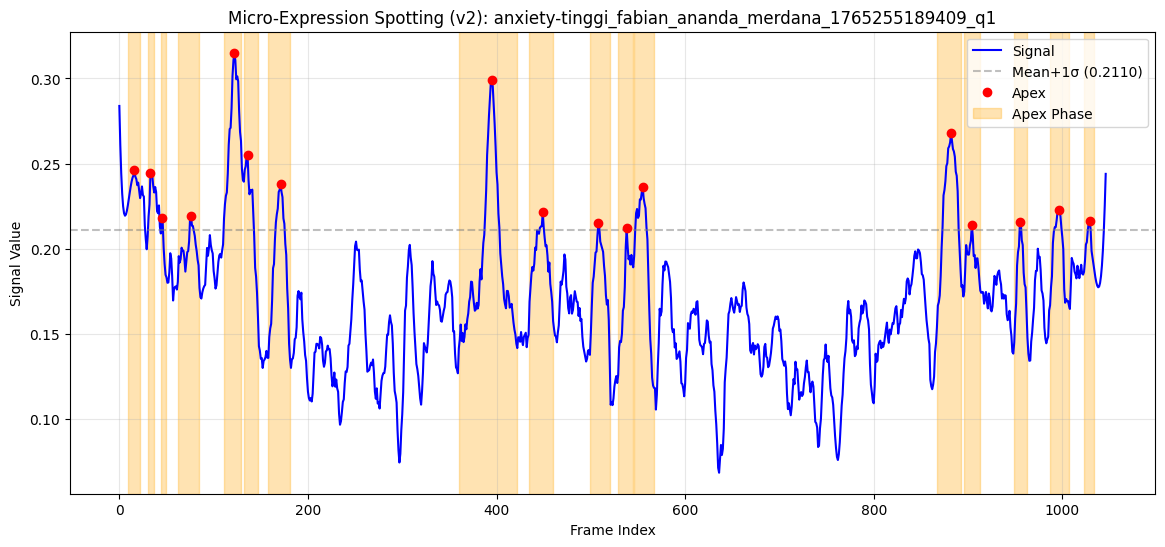

🔍 anxiety-tinggi_fabian_ananda_merdana_1765255189409_q2 | frames=639 | window=31 | polyorder=4
  ✅ Apex: 29 | Onset: 19 | Offset: 34 | Duration: 15
  ✅ Apex: 42 | Onset: 35 | Offset: 50 | Duration: 15
  ✅ Apex: 69 | Onset: 63 | Offset: 78 | Duration: 15
  ✅ Apex: 90 | Onset: 82 | Offset: 128 | Duration: 46
  ✅ Apex: 205 | Onset: 198 | Offset: 212 | Duration: 14
  ✅ Apex: 250 | Onset: 242 | Offset: 258 | Duration: 16
  ✅ Apex: 271 | Onset: 262 | Offset: 281 | Duration: 19
  ✅ Apex: 344 | Onset: 336 | Offset: 351 | Duration: 15
  ✅ Apex: 359 | Onset: 351 | Offset: 380 | Duration: 29
  ✅ Apex: 484 | Onset: 477 | Offset: 493 | Duration: 16
  ✅ Apex: 530 | Onset: 507 | Offset: 549 | Duration: 42


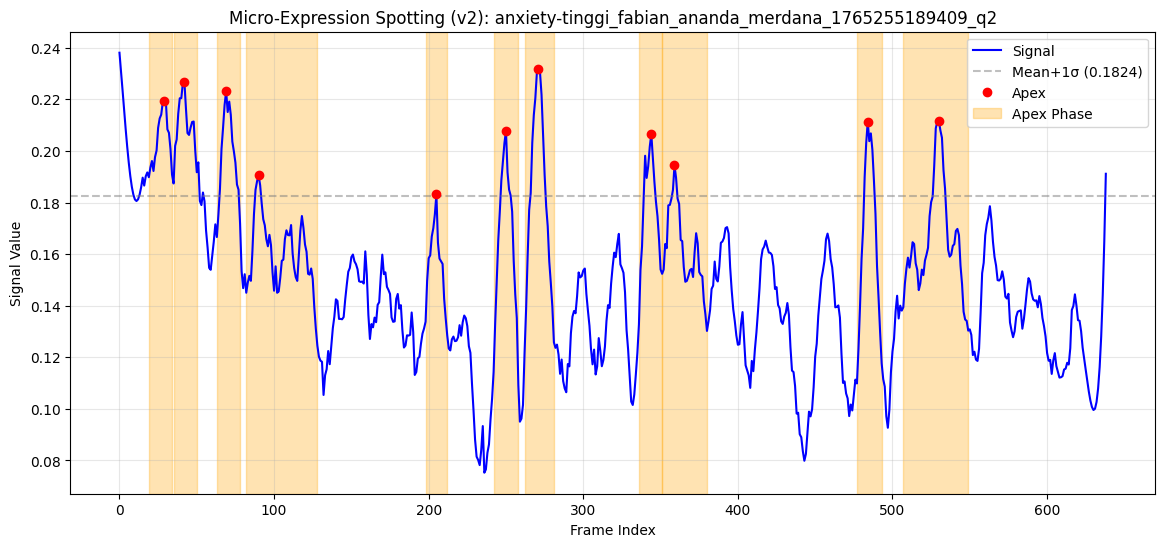

🔍 anxiety-tinggi_fabian_ananda_merdana_1765255189409_q3 | frames=449 | window=23 | polyorder=4
  ✅ Apex: 26 | Onset: 11 | Offset: 31 | Duration: 20
  ✅ Apex: 61 | Onset: 48 | Offset: 66 | Duration: 18
  ✅ Apex: 74 | Onset: 69 | Offset: 97 | Duration: 28
  ✅ Apex: 220 | Onset: 211 | Offset: 224 | Duration: 13
  ✅ Apex: 247 | Onset: 235 | Offset: 270 | Duration: 35
  ✅ Apex: 309 | Onset: 303 | Offset: 315 | Duration: 12
  ✅ Apex: 322 | Onset: 316 | Offset: 326 | Duration: 10
  ✅ Apex: 346 | Onset: 343 | Offset: 347 | Duration: 4
  ✅ Apex: 375 | Onset: 369 | Offset: 380 | Duration: 11
  ✅ Apex: 390 | Onset: 385 | Offset: 395 | Duration: 10
  ✅ Apex: 406 | Onset: 401 | Offset: 414 | Duration: 13
  ✅ Apex: 435 | Onset: 428 | Offset: 441 | Duration: 13


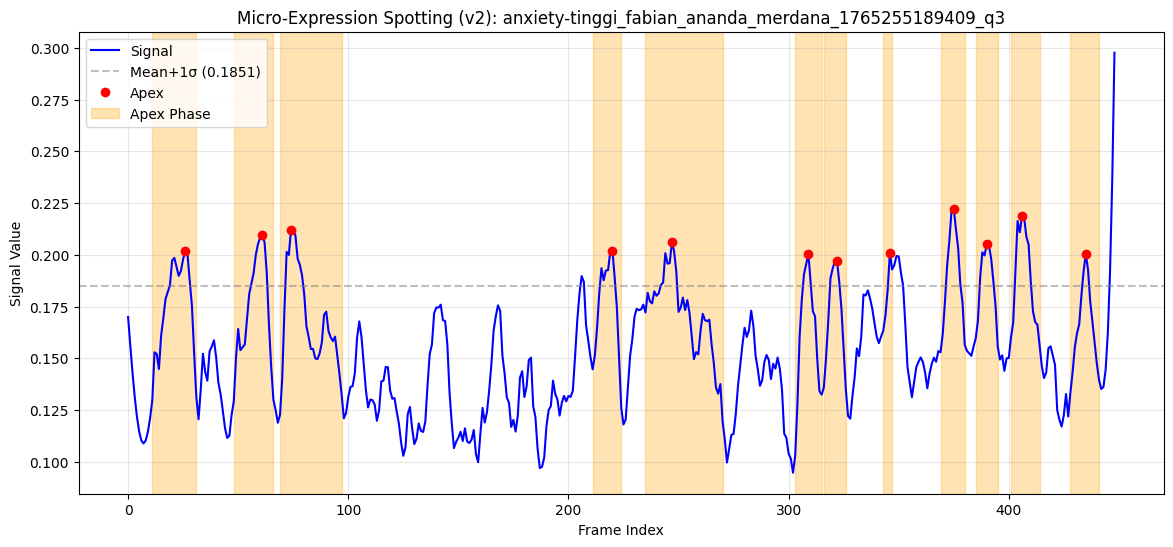

🔍 anxiety-tinggi_fabian_ananda_merdana_1765255189409_q4 | frames=405 | window=21 | polyorder=4
  ✅ Apex: 13 | Onset: 8 | Offset: 17 | Duration: 9
  ✅ Apex: 26 | Onset: 23 | Offset: 31 | Duration: 8
  ✅ Apex: 41 | Onset: 35 | Offset: 47 | Duration: 12
  ✅ Apex: 66 | Onset: 59 | Offset: 78 | Duration: 19
  ✅ Apex: 138 | Onset: 125 | Offset: 147 | Duration: 22
  ✅ Apex: 186 | Onset: 178 | Offset: 193 | Duration: 15
  ✅ Apex: 256 | Onset: 238 | Offset: 268 | Duration: 30
  ✅ Apex: 284 | Onset: 271 | Offset: 292 | Duration: 21
  ✅ Apex: 363 | Onset: 356 | Offset: 368 | Duration: 12
  ✅ Apex: 402 | Onset: 395 | Offset: 404 | Duration: 9


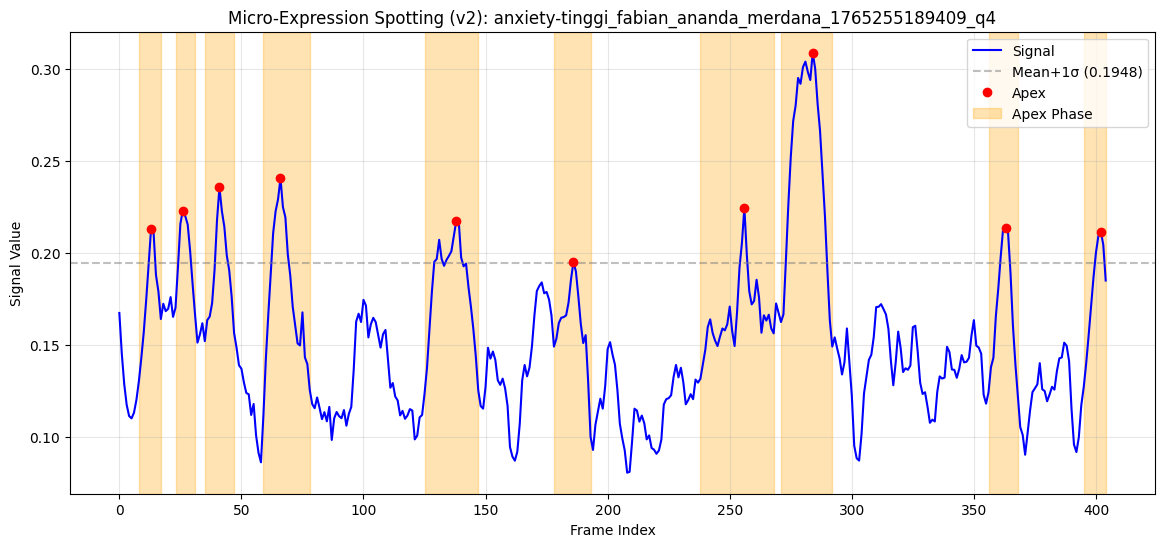

🔍 anxiety-tinggi_fabian_ananda_merdana_1765255189409_q5 | frames=438 | window=21 | polyorder=4
  ✅ Apex: 104 | Onset: 94 | Offset: 112 | Duration: 18
  ✅ Apex: 150 | Onset: 144 | Offset: 154 | Duration: 10
  ✅ Apex: 162 | Onset: 156 | Offset: 167 | Duration: 11
  ✅ Apex: 193 | Onset: 188 | Offset: 206 | Duration: 18
  ✅ Apex: 260 | Onset: 249 | Offset: 262 | Duration: 13
  ✅ Apex: 283 | Onset: 282 | Offset: 290 | Duration: 8
  ✅ Apex: 315 | Onset: 308 | Offset: 330 | Duration: 22
  ✅ Apex: 356 | Onset: 346 | Offset: 365 | Duration: 19
  ✅ Apex: 388 | Onset: 381 | Offset: 397 | Duration: 16
  ✅ Apex: 408 | Onset: 402 | Offset: 414 | Duration: 12


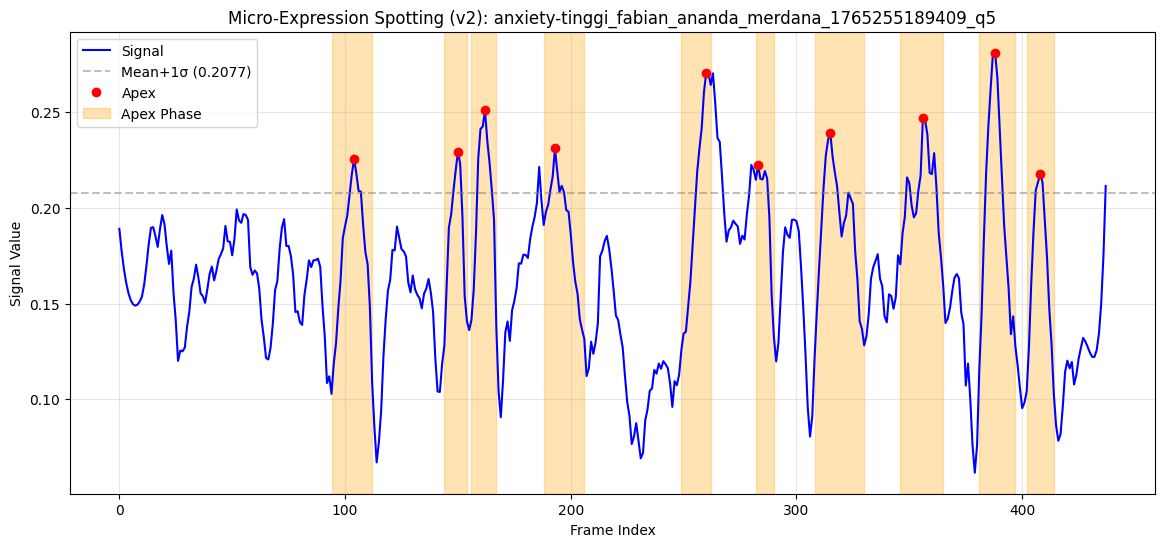

🔍 anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q1 | frames=385 | window=19 | polyorder=4
  ✅ Apex: 56 | Onset: 51 | Offset: 62 | Duration: 11
  ✅ Apex: 133 | Onset: 126 | Offset: 138 | Duration: 12
  ✅ Apex: 143 | Onset: 142 | Offset: 147 | Duration: 5
  ✅ Apex: 157 | Onset: 152 | Offset: 162 | Duration: 10
  ✅ Apex: 169 | Onset: 164 | Offset: 173 | Duration: 9
  ✅ Apex: 179 | Onset: 175 | Offset: 186 | Duration: 11
  ✅ Apex: 221 | Onset: 215 | Offset: 227 | Duration: 12
  ✅ Apex: 257 | Onset: 253 | Offset: 265 | Duration: 12
  ✅ Apex: 277 | Onset: 267 | Offset: 284 | Duration: 17
  ✅ Apex: 316 | Onset: 308 | Offset: 321 | Duration: 13
  ✅ Apex: 338 | Onset: 333 | Offset: 344 | Duration: 11
  ✅ Apex: 367 | Onset: 360 | Offset: 375 | Duration: 15


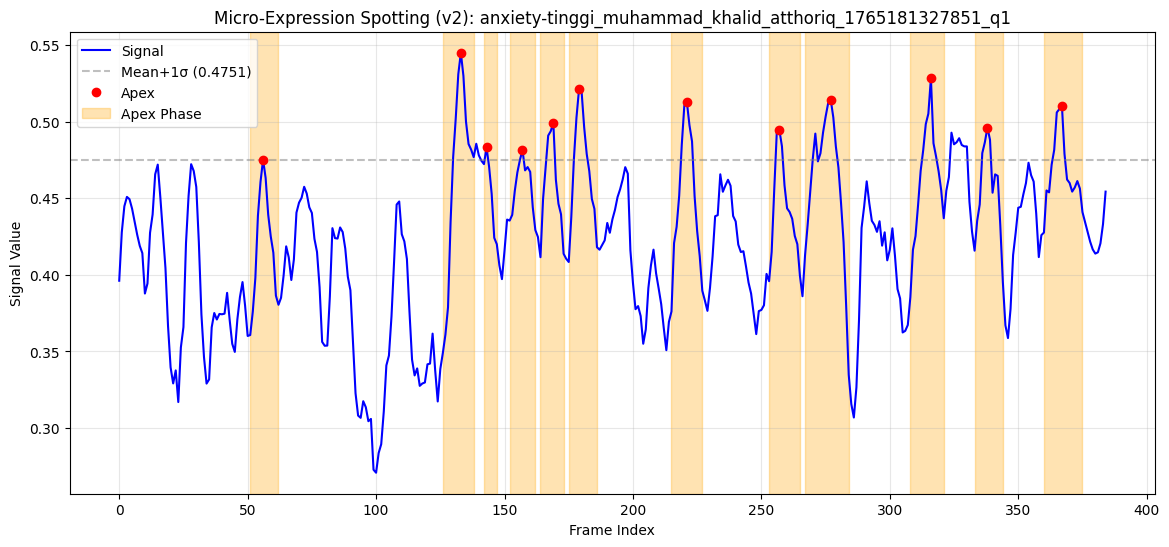

🔍 anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q2 | frames=398 | window=19 | polyorder=4
  ✅ Apex: 226 | Onset: 217 | Offset: 242 | Duration: 25
  ✅ Apex: 259 | Onset: 246 | Offset: 264 | Duration: 18
  ✅ Apex: 280 | Onset: 271 | Offset: 295 | Duration: 24
  ✅ Apex: 313 | Onset: 308 | Offset: 319 | Duration: 11
  ✅ Apex: 328 | Onset: 322 | Offset: 333 | Duration: 11
  ✅ Apex: 340 | Onset: 337 | Offset: 341 | Duration: 4
  ✅ Apex: 362 | Onset: 351 | Offset: 368 | Duration: 17
  ✅ Apex: 378 | Onset: 370 | Offset: 394 | Duration: 24


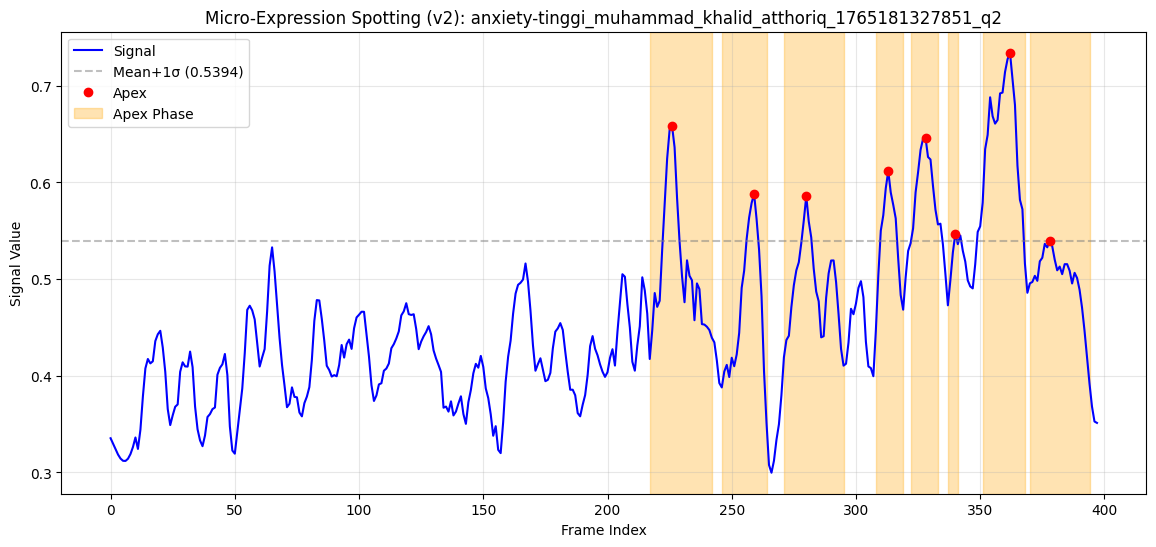

🔍 anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q3 | frames=376 | window=19 | polyorder=4
  ✅ Apex: 16 | Onset: 6 | Offset: 22 | Duration: 16
  ✅ Apex: 63 | Onset: 46 | Offset: 79 | Duration: 33
  ✅ Apex: 99 | Onset: 95 | Offset: 106 | Duration: 11
  ✅ Apex: 113 | Onset: 108 | Offset: 139 | Duration: 31
  ✅ Apex: 181 | Onset: 180 | Offset: 185 | Duration: 5
  ✅ Apex: 199 | Onset: 195 | Offset: 203 | Duration: 8
  ✅ Apex: 211 | Onset: 206 | Offset: 216 | Duration: 10
  ✅ Apex: 221 | Onset: 220 | Offset: 225 | Duration: 5
  ✅ Apex: 242 | Onset: 237 | Offset: 257 | Duration: 20
  ✅ Apex: 274 | Onset: 260 | Offset: 297 | Duration: 37
  ✅ Apex: 338 | Onset: 326 | Offset: 344 | Duration: 18
  ✅ Apex: 353 | Onset: 347 | Offset: 359 | Duration: 12
  ✅ Apex: 371 | Onset: 362 | Offset: 375 | Duration: 13


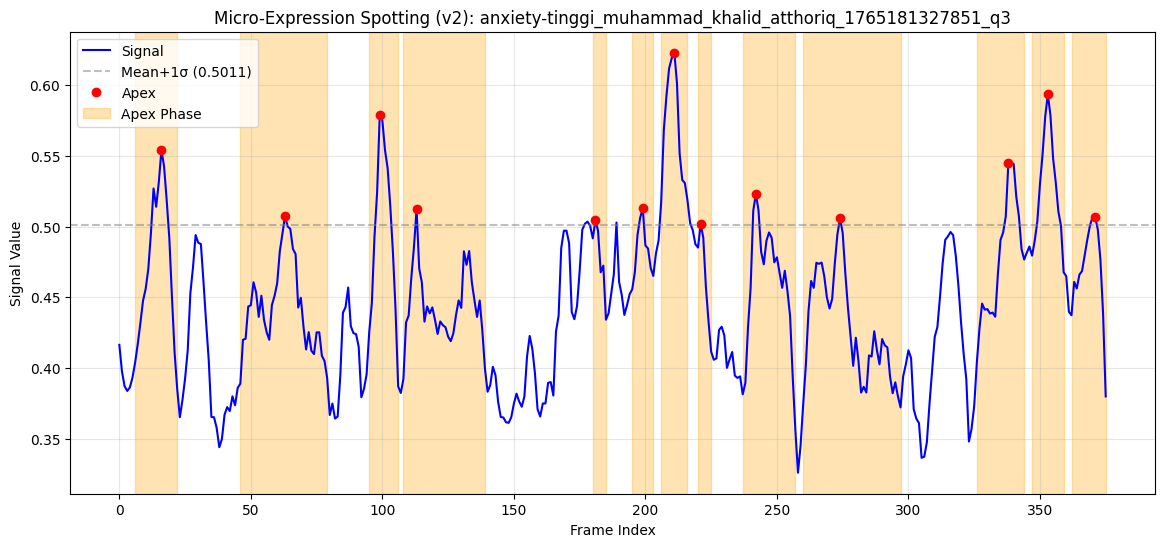

🔍 anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q4 | frames=262 | window=13 | polyorder=3
  ✅ Apex: 1 | Onset: 0 | Offset: 6 | Duration: 6
  ✅ Apex: 15 | Onset: 10 | Offset: 20 | Duration: 10
  ✅ Apex: 29 | Onset: 28 | Offset: 32 | Duration: 4
  ✅ Apex: 41 | Onset: 35 | Offset: 44 | Duration: 9
  ✅ Apex: 51 | Onset: 46 | Offset: 55 | Duration: 9
  ✅ Apex: 76 | Onset: 68 | Offset: 113 | Duration: 45


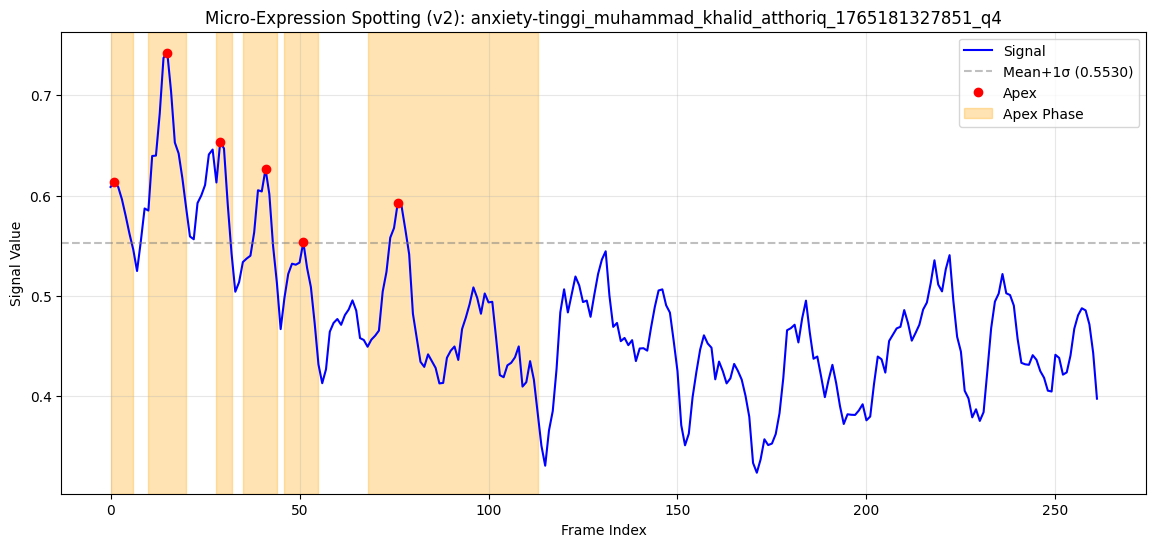

🔍 anxiety-tinggi_muhammad_khalid_atthoriq_1765181327851_q5 | frames=444 | window=23 | polyorder=4
  ✅ Apex: 104 | Onset: 88 | Offset: 111 | Duration: 23
  ✅ Apex: 134 | Onset: 129 | Offset: 143 | Duration: 14
  ✅ Apex: 154 | Onset: 146 | Offset: 163 | Duration: 17
  ✅ Apex: 173 | Onset: 168 | Offset: 180 | Duration: 12
  ✅ Apex: 189 | Onset: 182 | Offset: 197 | Duration: 15
  ✅ Apex: 239 | Onset: 231 | Offset: 244 | Duration: 13
  ✅ Apex: 255 | Onset: 250 | Offset: 260 | Duration: 10
  ✅ Apex: 268 | Onset: 263 | Offset: 282 | Duration: 19
  ✅ Apex: 314 | Onset: 309 | Offset: 320 | Duration: 11
  ✅ Apex: 353 | Onset: 345 | Offset: 373 | Duration: 28
  ✅ Apex: 432 | Onset: 398 | Offset: 443 | Duration: 45


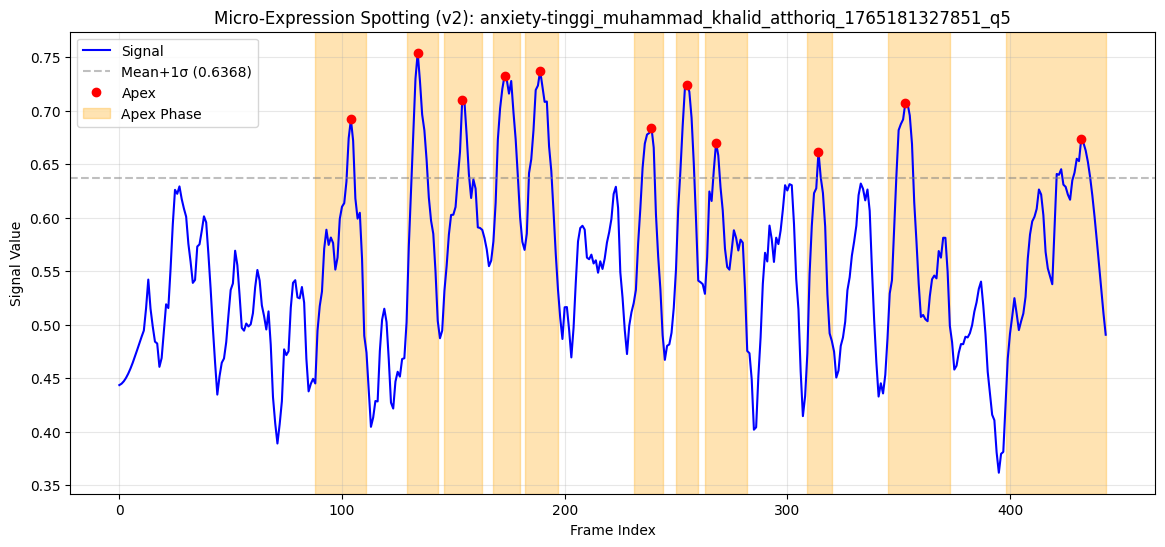

🔍 anxiety-tinggi_nova_eliza_maharani_1765181769652_q1 | frames=359 | window=17 | polyorder=4
  ✅ Apex: 60 | Onset: 49 | Offset: 66 | Duration: 17
  ✅ Apex: 104 | Onset: 91 | Offset: 108 | Duration: 17
  ✅ Apex: 114 | Onset: 110 | Offset: 119 | Duration: 9
  ✅ Apex: 124 | Onset: 120 | Offset: 129 | Duration: 9
  ✅ Apex: 147 | Onset: 143 | Offset: 153 | Duration: 10
  ✅ Apex: 159 | Onset: 155 | Offset: 165 | Duration: 10
  ✅ Apex: 249 | Onset: 237 | Offset: 255 | Duration: 18
  ✅ Apex: 270 | Onset: 267 | Offset: 275 | Duration: 8
  ✅ Apex: 280 | Onset: 275 | Offset: 283 | Duration: 8
  ✅ Apex: 299 | Onset: 298 | Offset: 303 | Duration: 5
  ✅ Apex: 315 | Onset: 309 | Offset: 337 | Duration: 28


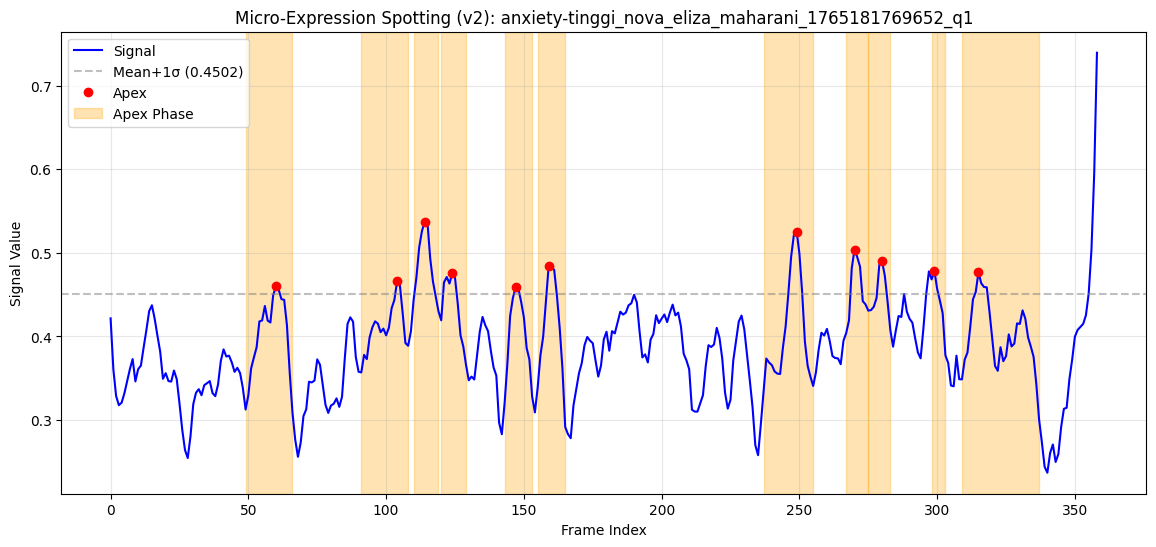

🔍 anxiety-tinggi_nova_eliza_maharani_1765181769652_q2 | frames=326 | window=17 | polyorder=4
  ✅ Apex: 43 | Onset: 36 | Offset: 47 | Duration: 11
  ✅ Apex: 54 | Onset: 50 | Offset: 67 | Duration: 17
  ✅ Apex: 82 | Onset: 77 | Offset: 93 | Duration: 16
  ✅ Apex: 104 | Onset: 97 | Offset: 110 | Duration: 13
  ✅ Apex: 135 | Onset: 126 | Offset: 142 | Duration: 16
  ✅ Apex: 151 | Onset: 147 | Offset: 155 | Duration: 8
  ✅ Apex: 166 | Onset: 161 | Offset: 172 | Duration: 11
  ✅ Apex: 289 | Onset: 284 | Offset: 316 | Duration: 32


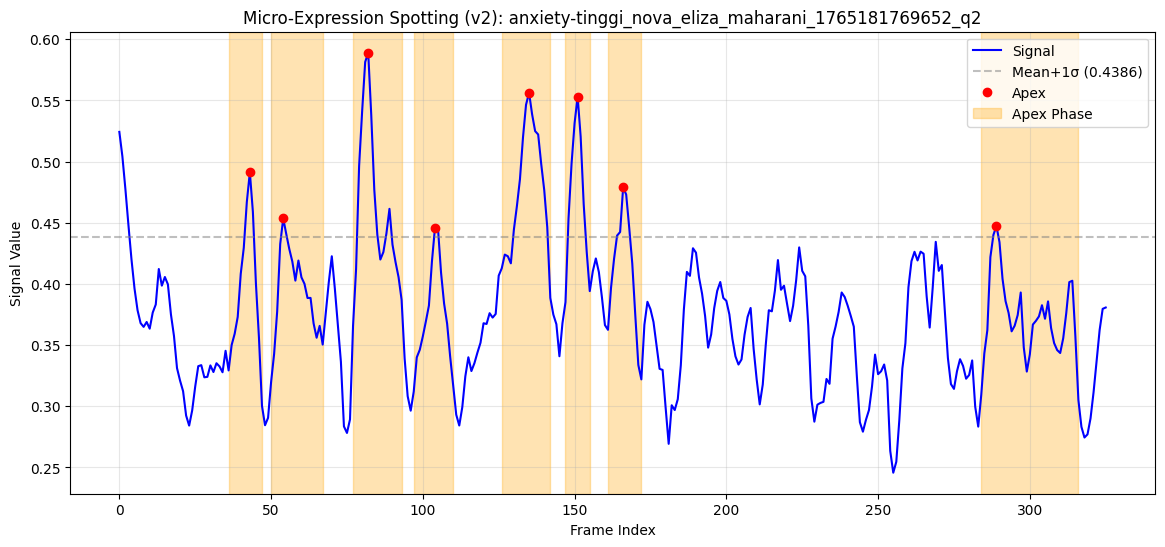

🔍 anxiety-tinggi_nova_eliza_maharani_1765181769652_q3 | frames=680 | window=31 | polyorder=4
  ✅ Apex: 103 | Onset: 92 | Offset: 111 | Duration: 19
  ✅ Apex: 127 | Onset: 115 | Offset: 137 | Duration: 22
  ✅ Apex: 213 | Onset: 200 | Offset: 223 | Duration: 23
  ✅ Apex: 259 | Onset: 248 | Offset: 265 | Duration: 17
  ✅ Apex: 272 | Onset: 266 | Offset: 278 | Duration: 12
  ✅ Apex: 289 | Onset: 285 | Offset: 298 | Duration: 13
  ✅ Apex: 317 | Onset: 308 | Offset: 326 | Duration: 18
  ✅ Apex: 357 | Onset: 347 | Offset: 369 | Duration: 22
  ✅ Apex: 396 | Onset: 382 | Offset: 408 | Duration: 26
  ✅ Apex: 439 | Onset: 418 | Offset: 473 | Duration: 55
  ✅ Apex: 575 | Onset: 553 | Offset: 589 | Duration: 36
  ✅ Apex: 632 | Onset: 626 | Offset: 640 | Duration: 14


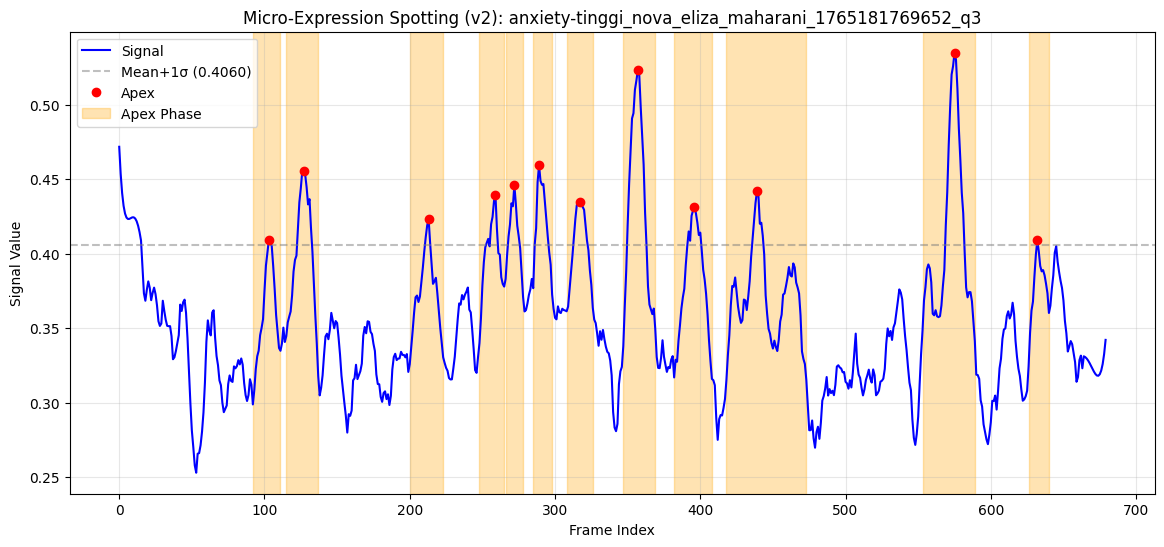

🔍 anxiety-tinggi_nova_eliza_maharani_1765181769652_q4 | frames=650 | window=31 | polyorder=4
  ✅ Apex: 95 | Onset: 86 | Offset: 101 | Duration: 15
  ✅ Apex: 107 | Onset: 106 | Offset: 118 | Duration: 12
  ✅ Apex: 251 | Onset: 245 | Offset: 261 | Duration: 16
  ✅ Apex: 271 | Onset: 262 | Offset: 281 | Duration: 19
  ✅ Apex: 314 | Onset: 307 | Offset: 324 | Duration: 17
  ✅ Apex: 348 | Onset: 337 | Offset: 355 | Duration: 18
  ✅ Apex: 437 | Onset: 399 | Offset: 442 | Duration: 43
  ✅ Apex: 456 | Onset: 448 | Offset: 463 | Duration: 15
  ✅ Apex: 498 | Onset: 488 | Offset: 520 | Duration: 32
  ✅ Apex: 562 | Onset: 551 | Offset: 583 | Duration: 32
  ✅ Apex: 613 | Onset: 609 | Offset: 624 | Duration: 15


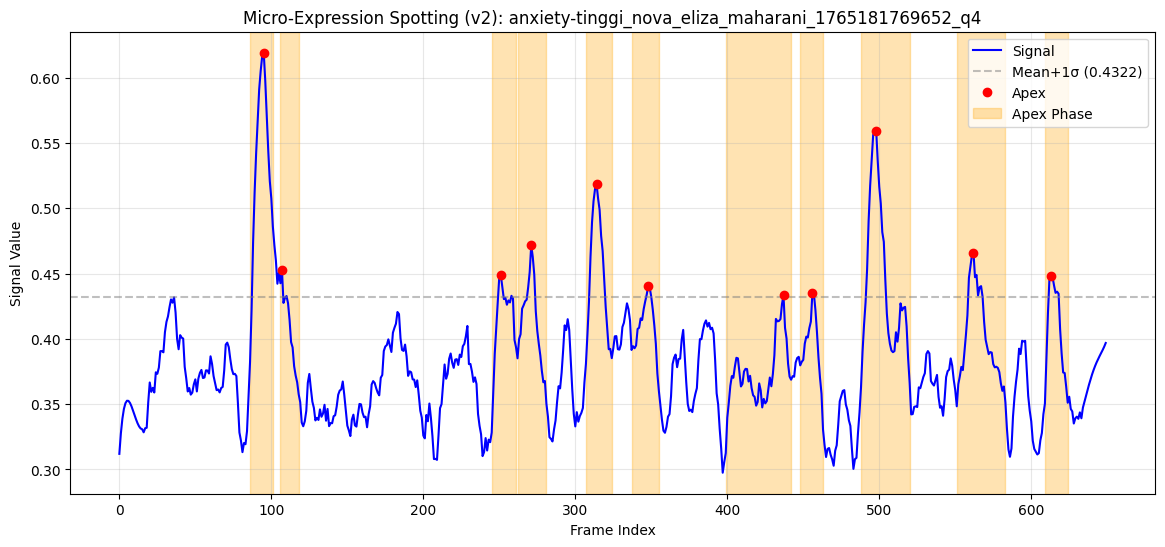

🔍 anxiety-tinggi_nova_eliza_maharani_1765181769652_q5 | frames=722 | window=31 | polyorder=4
  ✅ Apex: 3 | Onset: 0 | Offset: 13 | Duration: 13
  ✅ Apex: 97 | Onset: 72 | Offset: 109 | Duration: 37
  ✅ Apex: 242 | Onset: 208 | Offset: 249 | Duration: 41
  ✅ Apex: 272 | Onset: 259 | Offset: 310 | Duration: 51
  ✅ Apex: 368 | Onset: 360 | Offset: 376 | Duration: 16
  ✅ Apex: 385 | Onset: 377 | Offset: 407 | Duration: 30
  ✅ Apex: 483 | Onset: 476 | Offset: 506 | Duration: 30
  ✅ Apex: 532 | Onset: 516 | Offset: 540 | Duration: 24
  ✅ Apex: 565 | Onset: 552 | Offset: 582 | Duration: 30
  ✅ Apex: 677 | Onset: 666 | Offset: 683 | Duration: 17
  ✅ Apex: 691 | Onset: 685 | Offset: 699 | Duration: 14
  ✅ Apex: 714 | Onset: 704 | Offset: 720 | Duration: 16


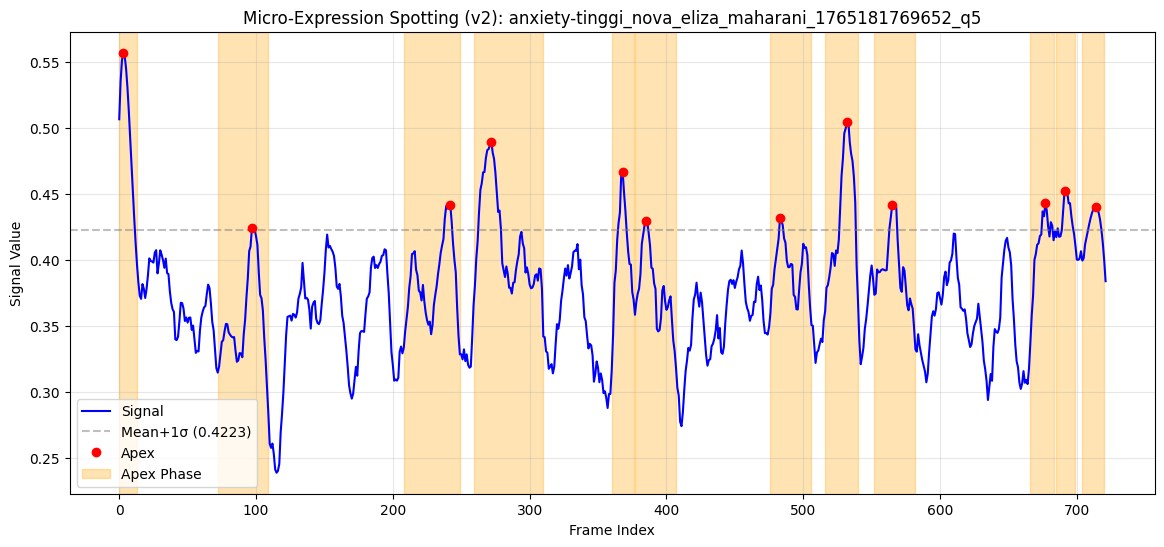


🎉 Step 3B done! Plots saved to ../output/plots_per_q_v2/


In [13]:
# ======================================================
# STEP 3B: ANALYZE & VISUALIZE (Per Question) — apex/ module
# ======================================================

# Micro-expression duration filter — hanya filter noise (durasi < MIN)
# Tidak ada batas atas agar tidak membuang micro-expression yang valid
MIN_PHASE_DURATION = 2  # frame minimum (hindari noise 0-1 frame)

# Initialize apex module classes
apex_detector = ApexPhase(
    distance_threshold=1,
    prominence_threshold=0.005,
    cutoff_ratio=0.3
)
visualizer = ApexPhaseVisualizer()

# Accumulator untuk summary statistics
all_stats = []

for npy_file in sorted(os.listdir(MAGNITUDES_DIR_Q)):
    if not npy_file.endswith(".npy"):
        continue

    q_name = os.path.splitext(npy_file)[0]
    mag_path = os.path.join(MAGNITUDES_DIR_Q, npy_file)
    raw_magnitudes = np.load(mag_path).tolist()

    # --- Adaptive Smoothing (ApexSmoother.smooth) ---
    try:
        smoothed = ApexSmoother.smooth(raw_magnitudes)
    except ValueError as e:
        print(f"⚠️ Skip {q_name}: {e}")
        continue

    wl = ApexSmoother.calculate_window_length(len(raw_magnitudes))
    po = ApexSmoother.calculate_polyorder(wl)
    print(f"🔍 {q_name} | frames={len(raw_magnitudes)} | window={wl} | polyorder={po}")

    # --- Apex Detection (with height threshold: mean + 1*std) ---
    signal_arr = np.array(smoothed)
    height_threshold = float(np.mean(signal_arr) + np.std(signal_arr))
    apex_indices = apex_detector.find_top_k_apex(smoothed, k=5, height=height_threshold)

    if len(apex_indices) == 0:
        print(f"  ⚠️ No apex detected above threshold ({height_threshold:.4f})")
        all_stats.append(dict(name=q_name, total_frames=len(raw_magnitudes), apex_count=0, phases=[]))
        continue

    # --- Phase Detection (onset/offset) ---
    phases = apex_detector.find_phase(smoothed, apex_indices)

    # --- Filter: hanya buang micro-noise (durasi sangat pendek) ---
    filtered_apex = []
    filtered_phases = {}
    for apex_idx in apex_indices:
        phase = phases[apex_idx]
        duration = phase['end'] - phase['start']
        if duration >= MIN_PHASE_DURATION:
            filtered_apex.append(apex_idx)
            filtered_phases[apex_idx] = phase
            print(f"  ✅ Apex: {apex_idx} | Onset: {phase['start']} | Offset: {phase['end']} | Duration: {duration}")
        else:
            print(f"  ❌ Apex: {apex_idx} | Duration: {duration} (filtered out, terlalu pendek < {MIN_PHASE_DURATION})")

    # Collect stats
    phase_durations = [filtered_phases[a]['end'] - filtered_phases[a]['start'] for a in filtered_apex]
    all_stats.append(dict(
        name=q_name,
        total_frames=len(raw_magnitudes),
        apex_count=len(filtered_apex),
        phases=phase_durations
    ))

    # --- Visualize ---
    if len(filtered_apex) > 0:
        save_path = os.path.join(PLOTS_DIR_Q, f"{q_name}.png")
        visualizer.plot_phases(
            signal=smoothed,
            apex_indices=filtered_apex,
            phases=filtered_phases,
            title=f"Micro-Expression Spotting (v2): {q_name}",
            save_path=save_path
        )
    else:
        print(f"  ⚠️ No valid phases after filtering")

print(f"\n🎉 Step 3B done! Plots saved to {PLOTS_DIR_Q}/")